<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QSVM_QNN_MalwareClassification_Barrue2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM and QNN for malware classification: Barrué and Quertier (2023) step by step

**Paper.** Grégoire Barrué and Tony Quertier, *Quantum Machine Learning for Malware Classification*, arXiv:2305.09674v3 [cs.CR], 2023. https://arxiv.org/abs/2305.09674

**What this notebook does.** It rebuilds the paper's two quantum classifiers for Windows PE malware, on the same task (malicious versus benign executable files) and with the same protocol:

1. a **Quantum Support Vector Machine** (QSVM) with four feature maps (`ZZ`, `Pauli (X, Y, ZZ)`, `ZZphi`, `Z`), compared with classical SVMs (linear, polynomial, RBF, sigmoid), for different numbers of training samples and of qubits (paper Tables 3 to 11);
2. a **Quantum Neural Network** (QNN, 2 ancilla qubits, layers of `RY` rotations and CNOTs) trained with the **parameter-shift rule**, with the **SPSB** gradient estimator, with **data re-uploading**, and with both, compared with classical neural networks (paper Tables 12 to 57).

Everything is explained in plain language before each step. The data are **downloaded by the notebook itself** (a public Hugging Face copy of the BODMAS malware dataset), nothing is faked, and every quantum model is compared with classical models that receive exactly the same inputs.

**How to run.** In Google Colab choose a **CPU** runtime and use *Runtime > Run all*. `FAST_MODE = True` (default of this file, see the configuration cell) is a class demonstration (about 10 minutes on an idle laptop CPU; 30 minutes when the machine is heavily shared); set `FAST_MODE = False` for the full budgets (see the configuration cell for the exact numbers and the run time). No GPU, no IBM account and no Hugging Face token are needed (the dataset is public). The optional hardware cell is skipped unless you set `IBM_TOKEN`.

**What you get at the end.** Executed tables and figures for every experiment, the paper's numbers side by side with this notebook's numbers (verdict per claim: reproduced, not reached, exceeded, cannot be checked), and a critical reading with student exercises.

**About the committed outputs.** The outputs saved in this file are from one complete, error-free run with `FAST_MODE = True` (30.5 min wall-clock on a CPU shared with other jobs). The full budgets (`FAST_MODE = False`) were **not** executed for this file because they are estimated to take several hours on that machine; the cells that need them (sizes above 2 000 files, 7-qubit models, learning-rate scan, 10-epoch deep models, Table 55) show the verdict `cannot be checked (not run in FAST_MODE)`.

## The paper in one page

* **Problem.** Classify Windows executables (PE files) as malicious or benign. The authors ask whether quantum machine learning could help (generalisation to unseen malware), and run two quantum models on a classical simulator and, for one small test, on IBM hardware. The work is explicitly **exploratory**.
* **Data.** BODMAS (57 293 malicious, 77 142 benign) and PEMachineLearning (114 737 malicious, 86 812 benign). Two preprocessings: **"Images"** (the file's bytes as a 64 x 64 grayscale picture, then **PCA** to 3, 4, 6 or 7 components = qubits) and **"OIF"** (*Ordered Importance Features*: 10 EMBER features chosen by forward selection, plus an *import maliciousness score*; the first `n` features feed `n` qubits).
* **Model 1: QSVM** (Qiskit Global Summer School Lab 3 style). Feature maps `ZZ` (2 layers, linear entanglement, `phi_jk = (pi - x_j)(pi - x_k)`), `Pauli` (X, Y, ZZ), `ZZphi` (`phi_jk = sin(pi - x_j) sin(pi - x_k)`) and `Z`; kernel from state fidelities; SVM; accuracy and F1 against linear / polynomial / RBF / sigmoid SVMs; training sets from 500 to 16 000 files (tests 100 to 4 000); 3 to 7 qubits; a 100/20 run on IBM hardware.
* **Model 2: QNN** (after Chalumuri et al.). `N` data qubits (angles in `[0, pi/2]`) + 2 ancillas, `L` layers of `RY` + CNOT entanglement + ancilla rotations, softmax cross-entropy on the two ancilla `<Z>`; trained on **1 000** files and tested on 200 or 4 000; layers 1 to 3 and 4 or 7 qubits (1 epoch, lr 0.1), learning rates 0.01 / 0.1 / 0.5, and deeper models (4 qubits / 5 or 10 layers / 10 epochs / lr 0.05; 7 qubits / 5 layers / 5 epochs / lr 0.1). Four training variants: parameter-shift, **SPSB** (batch 32), **data re-uploading**, both. Classical neural networks with matching sizes (batch 1 or 16) as comparison.
* **Claims.** (1) QSVM matches the classical SVMs on Images (0.78 to 0.82) and on small samples with 7 qubits is up to 2.5 points better; (2) OIF gives much higher scores than Images (F1 0.81 to 0.94); (3) the QNN never beats the classical NN, and learns badly on Images (0.5 to 0.78), better on OIF (0.5 to 0.88); (4) data re-uploading raises the QNN to near the classical NN; (5) SPSB is far cheaper than the parameter-shift rule at similar final accuracy; (6) QSVM on IBM hardware gives results similar to classical SVMs.

### What follows the paper and what had to be chosen

The most important deviation first: **the paper's inputs cannot be rebuilt from public data.** Its *Images* come from the raw bytes of benign and malicious files (benign executables are not redistributable and malware binaries should not be downloaded in a classroom), and its *OIF* score comes from a private import-confidence table of the first author's team. The notebook uses the public **BODMAS feature vectors** and builds an image-like view and an OIF-like view from them. The absolute accuracies are therefore **not directly comparable** with the paper's; the trends are what can be tested.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | BODMAS + PEMachineLearning, raw PE files | **BODMAS only**, public Hugging Face copy `it4lia/BODMAS_cleaned` (EMBER-style 2 326-column vectors, labels, families), balanced random draws of `POOL_TRAIN + POOL_TEST` files |
| "Images" input | 64 x 64 grayscale picture of the file bytes (Nataraj) | **32 x 16 byte-statistics picture** (byte histogram over byte-entropy histogram, 8-bit, `# CHOICE:` square-root contrast), 512 pixels |
| "OIF" input | 10 forward-selected EMBER features + private import maliciousness score | **import score** = logistic regression on the 1 280 hashed import columns (out-of-fold on its own training rows) + **10 features chosen by forward selection** (decision-tree validation accuracy, corr. filter 0.95), fitted on `TRAIN_FIT_N` training files |
| Dimension reduction | PCA to 3, 4, 6, 7 (Images); first `n` ordered features (OIF) | the same, fitted on the training files only |
| Angle scaling | not stated | `MinMaxScaler((0, pi))` for the QSVM, `((0, pi/2))` for the QNN, fitted on training files, test clipped (`# CHOICE:`) |
| Kernel bandwidth | not stated (none) | an overall angle scale from `BW_GRID`, picked on a validation split of the training files (`# CHOICE:`); the classical SVMs use scikit-learn defaults as in the paper, plus an extra tuned RBF and a random forest |
| Qubits of Tables 3, 4, 8, 9 | not stated; Table 5 shows that 4 gives the same numbers | 4 (`# CHOICE:`) |
| OIF QSVM sizes | Tables 8 to 10 are images in the PDF and cannot be extracted | computed and shown; only Table 11 (F1 by qubits) can be compared |
| QSVM entanglement | "linear" (Figure 2) | linear for ZZ, ZZphi and Pauli, `reps = 2` |
| Samples | one draw per table cell | `REPS` random draws for sizes up to 2 000 (mean and std), one draw above |
| QNN entangler | CNOT gates between all data and ancilla qubits (figure not in the text) | CNOT chain `q0 -> q1 -> ... -> q(N+1)` (`# CHOICE:`) |
| QNN loss | cross-entropy | softmax cross-entropy on the two ancilla `<Z>` values (`# CHOICE:` logits = expectation values) |
| QNN initial weights | not stated | uniform in `[-pi, pi]` (`# CHOICE:`) |
| QNN gradients | parameter-shift (3 evaluations per parameter) and SPSB | exact gradient via the adjoint method, asserted equal to the +-pi/2 parameter-shift gradient; SPSB with `eps = 0.1` (`# CHOICE:`), batch 32, one random sign direction per file |
| QNN epoch curves | accuracy after each epoch (training set not stated) | training accuracy on the 1 000 training files after each epoch |
| Test sets | 200 or 4 000 test files | the first 200 of the same balanced test set, or `QNN_TEST_BIG` files (4 000 in the full run, 1 000 in FAST) |
| Classical NN | Keras, width not stated | scikit-learn `MLPClassifier`, `NN_HIDDEN_WIDTH` ReLU units per layer, plain SGD, same lr / layers / epochs / inputs, batch 1 (protocol A) or 16 (protocol B) |
| Seeds | one run per cell | 1 seed in the 1-epoch grid and the lr scan, `QNN_DEEP_SEEDS` seeds for the deep models |
| IBM hardware (Table 7) | real device | not available: ideal simulation shown, optional cell with `IBM_TOKEN` |
| Simulator | Qiskit | exact NumPy state-vector simulators asserted equal to Qiskit (section on circuits) |

## 0. Set-up: install, configuration, imports

The cell below installs the tested library versions (Colab already has numpy, pandas, scikit-learn and matplotlib). The guard avoids reinstalling when the libraries are already importable. If Colab asks for a restart after the installation, use *Runtime > Restart session* and run all cells again.

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib.  The guard avoids reinstalling in a local environment.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("qiskit", "qiskit_machine_learning", "huggingface_hub", "pylatexenc", "requests", "sklearn"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "pylatexenc", "huggingface_hub", "requests"])
    print("Installed. If a later import fails, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")

All libraries already available, nothing to install.


### Configuration

Every tunable constant lives in the next cell. `FAST_MODE = True` shrinks the data pools, the sample sizes of the QSVM tables and the QNN grid so that the whole notebook runs in a few minutes. `FAST_MODE = False` follows the paper's budgets as far as an exact CPU simulation allows (sample sizes up to 16 000 / 4 000 for the QSVM, the three deep QNN set-ups of the paper's appendix, the learning-rate scan, 4 000 test files, and an extra 10 000-sample SPSB run); its run time was not measured for this file (the committed outputs are from the FAST run); expect several hours on a shared CPU. The remark about 'about 90 min' in the comment of the configuration cell is an estimate, not a measurement.

In [2]:
import os
SEED = 42
FAST_MODE = True            # True: class demo (a few minutes).  False: the paper's budgets (about 90 min on a laptop CPU).

DATA_DIR = "qc303_data"     # cache for the downloaded rows (a few tens of MB in FAST mode, ~190 MB in full mode)
CLEAN_CACHE_AT_END = True   # delete cached files above 50 MB in the last cell (Colab: harmless)
IBM_TOKEN = ""              # optional: paste an IBM Quantum token to run the hardware cell; empty = skipped
HF_REPO = "it4lia/BODMAS_cleaned"   # public Hugging Face copy of BODMAS (no token needed)

# ---- data pools: class-balanced PE-file records drawn once from BODMAS (rows = files)
POOL_TRAIN, POOL_TEST = (2400, 1000) if FAST_MODE else (16000, 4000)
TRAIN_FIT_N = 1500 if FAST_MODE else 4000     # training rows used to fit the forward selection / import score (OIF view)
BLOCK = 40                                    # rows fetched per HTTP range request (label-pure blocks)

# ---- QSVM (paper section 2).  Sizes are (train, test) pairs of Table 3 / Table 4
QSVM_SIZES = [(500, 100), (1000, 200), (2000, 400)] if FAST_MODE else \
             [(500, 100), (1000, 200), (2000, 400), (4000, 800), (8000, 1600), (16000, 4000)]
QSVM_QUBITS = 4                                # default number of qubits / PCA components / features of Tables 3, 4, 8, 9
QUBIT_SWEEP = ({3: (1000, 200), 4: (1000, 200), 6: (1000, 200), 7: (1000, 200)} if FAST_MODE else
               {3: (2000, 400), 4: (2000, 400), 6: (1000, 200), 7: (1000, 200)})   # Tables 5, 6, 10, 11
REPS = 2 if FAST_MODE else 5                   # random re-draws of the sample for sizes with <= 2000 training files
BW_GRID = (0.25, 0.5, 1.0)                     # kernel bandwidth = angle range scale, tuned on a validation split of the training data
SVM_C = 1.0                                    # sklearn default C, as the paper's classical SVMs

# ---- QNN (paper section 3 and 4)
QNN_TRAIN = 1000                               # training files of every QNN run (paper: 1000)
QNN_TEST_SMALL = 200                           # paper protocol A: 1000 train / 200 test
QNN_TEST_BIG = 1000 if FAST_MODE else 4000     # paper protocol B: 1000 train / 4000 test
QNN_QUBITS = [4] if FAST_MODE else [4, 7]      # data qubits of the 1-epoch grid (Tables 12 to 28)
QNN_LAYERS = [1, 2, 3]
QNN_GRID_LR = 0.1                              # paper: lr 0.1, one epoch
QNN_LR_SCAN = [] if FAST_MODE else [0.01, 0.5] # extra learning rates for 2 layers (Tables 30 to 38; 0.1 comes from the grid)
QNN_DEEP = ([(4, 5, 3, 0.05)] if FAST_MODE else   # (data qubits, layers, epochs, lr) of the deeper models (Tables 14 to 29, 39 to 57)
            [(4, 5, 10, 0.05), (4, 10, 10, 0.05), (7, 5, 5, 0.1)])
QNN_DEEP_SEEDS = [SEED] if FAST_MODE else [SEED, SEED + 1]
QNN_SPSB_BATCH, QNN_SPSB_EPS = 32, 0.1         # paper: batch 32 for SPSB; the finite-difference step is not given (CHOICE)
QNN_SPSB_BIG_TRAIN = 0 if FAST_MODE else 10000 # Table 55: SPSB, OIF, 7 qubits, 5 layers, 5 epochs, 10 000 training files
NN_HIDDEN_WIDTH = 8                            # width of the hidden layers of the classical network (not given in the paper: CHOICE)
TOL_ACC, TOL_F1 = 0.02, 0.02                   # "reproduced" if within 2 accuracy points / 0.02 F1

os.makedirs(DATA_DIR, exist_ok=True)
print(f"FAST_MODE={FAST_MODE}  pool={POOL_TRAIN}+{POOL_TEST}  QSVM sizes={QSVM_SIZES}  QNN grid qubits={QNN_QUBITS}")

FAST_MODE=True  pool=2400+1000  QSVM sizes=[(500, 100), (1000, 200), (2000, 400)]  QNN grid qubits=[4]


In [3]:
import io, json, time, math, warnings, itertools, collections
from math import pi
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import hf_hub_url, hf_hub_download
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, z_feature_map, pauli_feature_map
from qiskit.quantum_info import Statevector, SparsePauliOp
import qiskit_machine_learning
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import display
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})

# Hugging Face token: only needed for gated repositories (this dataset is public).  Resolved here and nowhere else.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED); algorithm_globals.random_seed = SEED
rng_master = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)
T_NOTEBOOK = time.time()

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: BODMAS PE files

**What the paper used.** Two datasets of Windows *Portable Executable* (PE) files, **BODMAS** (57 293 malicious, 77 142 benign) and **PEMachineLearning** (114 737 malicious, 86 812 benign). Both were shared as raw binaries or private extractions, and the paper turns each file into two inputs: the **"Images"** data (the file's bytes drawn as a 64 x 64 grayscale picture, Nataraj et al. 2011) and the **"OIF"** data (*Ordered Importance Features*: 10 hand-picked EMBER features chosen by forward selection plus an *import maliciousness score* that comes from the first author's team).

**What is publicly available.** Raw executables (especially the benign ones) cannot be redistributed and it is not appropriate to download malware binaries in a teaching notebook. The Hugging Face repository [`it4lia/BODMAS_cleaned`](https://huggingface.co/datasets/it4lia/BODMAS_cleaned) offers the **EMBER-style static feature vector of every BODMAS file** (2 326 numbers: byte histogram, byte-entropy histogram, string statistics, header, sections, hashed imports, exports, data directories), the label (benign / malware), the malware family and a timestamp. Its feature matrix is a 1.25 GB raw `float32` file, so the notebook fetches only the rows it needs with HTTP range requests (label-pure blocks of 40 rows), in the order given by the seed.

**Consequences (documented in the table at the top).**
* The *Images* data cannot be rebuilt from raw bytes. The closest honest substitute available for every BODMAS file is the pair of **byte-statistics pictures** that EMBER stores: the 256-bin *byte histogram* and the 16 x 16 *byte-entropy histogram* (Saxe and Berlin 2015, itself a 2-D image of how byte values and local entropy co-occur). They are drawn as a 32 x 16 grayscale picture (8-bit pixels) and then handled exactly like the paper's images: pixels -> PCA to `k` components -> angles.
* The *OIF* data are rebuilt with the same recipe on BODMAS' own features: an *import score* (here a supervised score computed from the 1 280 hashed import columns, because the paper's score is not published), followed by **forward selection** of 10 features, ordered by selection. Everything is fitted on training rows only.
* PEMachineLearning is not used (no public feature or image version with a matching label set). All numbers below are therefore on BODMAS alone.

In [4]:
FEAT = 2326                       # columns of the BODMAS feature matrix (EMBER 2381 minus 55 constant columns)
IMPORT_COLS = np.arange(888, 2168)   # the 1 280 hashed import columns (256 library + 1 024 function bins), located by inspection
IMG_COLS = np.arange(0, 512)         # byte histogram (0-255) and byte-entropy histogram (256-511)
SEED_POOL = SEED

def _fetch(args):
    url, first_row, nrows = args
    headers = {"Range": f"bytes={first_row * FEAT * 4}-{(first_row + nrows) * FEAT * 4 - 1}"}
    if HF_TOKEN:
        headers["Authorization"] = "Bearer " + HF_TOKEN
    last = None
    for attempt in range(5):
        try:
            r = requests.get(url, headers=headers, timeout=180)
            if r.status_code == 206 and len(r.content) == nrows * FEAT * 4:
                return np.frombuffer(r.content, dtype=np.float32).reshape(nrows, FEAT)
            last = f"HTTP {r.status_code}, {len(r.content)} bytes"
        except Exception as e:                      # network hiccup: retry
            last = repr(e)
        time.sleep(2 * (attempt + 1))
    raise RuntimeError("could not fetch rows %d..%d: %s" % (first_row, first_row + nrows, last))

def build_pool(n_train, n_test, seed):
    cache = os.path.join(DATA_DIR, f"bodmas_pool_{n_train}_{n_test}_{seed}.npz")
    meta_path = hf_hub_download(HF_REPO, "bodmas_clean_metadata.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
    meta = pd.read_parquet(meta_path)
    if os.path.exists(cache):
        z = np.load(cache)
        return z["X"], z["y"], z["rowidx"], z["tr"], z["te"], meta
    y_all = meta["label_int"].to_numpy()
    R = len(y_all); nb = R // BLOCK
    Yb = y_all[: nb * BLOCK].reshape(nb, BLOCK)
    pure = Yb.min(1) == Yb.max(1)
    rng = np.random.default_rng(seed)
    per_class = (n_train + n_test) // 2
    n_blocks = math.ceil(per_class / BLOCK)
    url = hf_hub_url(HF_REPO, "bodmas_clean_X.npy", repo_type="dataset")
    rows_by_class, X_by_class = {}, {}
    for c in (0, 1):
        cand = np.flatnonzero(pure & (Yb[:, 0] == c))
        pick = rng.choice(cand, n_blocks, replace=False)
        t0 = time.time()
        with ThreadPoolExecutor(4) as ex:
            parts = list(ex.map(_fetch, [(url, int(b) * BLOCK, BLOCK) for b in pick]))
        Xc = np.vstack(parts); rc = (pick[:, None] * BLOCK + np.arange(BLOCK)[None]).ravel()
        order = rng.permutation(len(rc))[:per_class]
        rows_by_class[c], X_by_class[c] = rc[order], Xc[order]
        print(f"class {c}: fetched {len(pick)} blocks ({Xc.nbytes / 1e6:.0f} MB) in {time.time() - t0:.0f} s", flush=True)
    half_te = n_test // 2
    X = np.vstack([X_by_class[0][half_te:], X_by_class[1][half_te:], X_by_class[0][:half_te], X_by_class[1][:half_te]])
    rowidx = np.concatenate([rows_by_class[0][half_te:], rows_by_class[1][half_te:], rows_by_class[0][:half_te], rows_by_class[1][:half_te]])
    y = y_all[rowidx]
    n0, n1 = per_class - half_te, per_class - half_te
    def interleave(a, b):                               # prefixes of the result are class-balanced
        out = np.empty(len(a) + len(b), dtype=int); out[0::2][:len(a)] = a; out[1::2][:len(b)] = b; return out
    tr = interleave(np.arange(0, n0), np.arange(n0, n0 + n1))
    te = interleave(np.arange(n0 + n1, n0 + n1 + half_te), np.arange(n0 + n1 + half_te, n0 + n1 + 2 * half_te))
    np.savez(cache, X=X, y=y, rowidx=rowidx, tr=tr, te=te)
    return X, y, rowidx, tr, te, meta

t0 = time.time()
X_RAW, Y_ALL, ROWIDX, TR_ALL, TE_ALL, META = build_pool(POOL_TRAIN, POOL_TEST, SEED_POOL)
print(f"pool ready in {time.time() - t0:.0f} s: X {X_RAW.shape} float32 ({X_RAW.nbytes / 1e6:.0f} MB), "
      f"train pool {len(TR_ALL)} rows, test pool {len(TE_ALL)} rows, label counts {np.bincount(Y_ALL).tolist()} (0 = benign, 1 = malware)")
POOL_META = META.iloc[ROWIDX].reset_index(drop=True)
POOL_FAMILY = POOL_META["family"].fillna("benign").astype(str).to_numpy()
POOL_YEAR = pd.to_datetime(POOL_META["timestamp"], utc=True).dt.year.fillna(0).astype(int).to_numpy()   # 0 = timestamp missing
print("test and train rows are disjoint:", len(set(ROWIDX[TR_ALL]) & set(ROWIDX[TE_ALL])) == 0)

pool ready in 4 s: X (3400, 2326) float32 (32 MB), train pool 2400 rows, test pool 1000 rows, label counts [1700, 1700] (0 = benign, 1 = malware)
test and train rows are disjoint: True


### The two views of the data

* **Images view.** For each file, the byte histogram (256 values, row = high nibble of the byte, column = low nibble) and the 16 x 16 byte-entropy histogram are each rescaled to 0..255 (square-root contrast, so rare bytes stay visible) and stacked into one **32 x 16 grayscale image** (`uint8`). The 512 pixels play the role of the paper's 4 096 pixels.
* **OIF view.** Two steps, both fitted on the first `TRAIN_FIT_N` training rows only. (1) An **import score**: a logistic regression on the 1 280 hashed import columns gives each file a probability of being malware (for the rows it was trained on, an out-of-fold probability from 5-fold cross-validation, so that the score is never computed by a model that saw that file's label). (2) **Forward selection**: starting from the import score, add one feature at a time (from the 200 columns with the highest ANOVA F-value, skipping the import columns and any column correlated above 0.95 with a chosen one) that most increases the validation accuracy of a small decision tree; 10 features are kept. The result has 11 columns, ordered by importance: `[import score, f1, ..., f10]`. Heavy-tailed raw columns are first compressed with `sign(x) log(1+|x|)`.

In [5]:
# ---------------------------------------------------------------- Images view (32 x 16 byte-statistics picture, 8-bit)
def to_images(Xb):
    h, e = Xb[:, :256], Xb[:, 256:512]
    def px(a):
        return np.round(255 * np.sqrt(a / np.maximum(a.max(1, keepdims=True), 1e-12))).astype(np.uint8)
    return np.concatenate([px(h).reshape(-1, 16, 16), px(e).reshape(-1, 16, 16)], axis=1)      # (n, 32, 16)

IMAGES = to_images(X_RAW)                                  # CHOICE: sqrt contrast, per-file maximum scaling
IMG_FLAT = IMAGES.reshape(len(IMAGES), -1).astype(np.float32) / 255.0
print("Images view:", IMAGES.shape, IMAGES.dtype)

# ---------------------------------------------------------------- OIF view (import score + 10 forward-selected features)
def slog(a):
    return np.sign(a) * np.log1p(np.abs(a))

XLOG = slog(X_RAW.astype(np.float64)).astype(np.float32)   # fixed monotone transform: no fitting involved
FIT = TR_ALL[:TRAIN_FIT_N]                                  # balanced prefix of the training pool
t0 = time.time()

# (1) import score: out-of-fold probabilities for the FIT rows, full-fit probabilities for every other row
imp_sc = StandardScaler().fit(XLOG[FIT][:, IMPORT_COLS])
Z_imp = imp_sc.transform(XLOG[:, IMPORT_COLS])
imp_score = np.zeros(len(XLOG))
lr_kw = dict(C=0.05, max_iter=300)                          # CHOICE: strong L2 regularisation for a 1 280-column sparse block
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(FIT, Y_ALL[FIT]):
    m = LogisticRegression(**lr_kw).fit(Z_imp[FIT[a]], Y_ALL[FIT[a]])
    imp_score[FIT[b]] = m.predict_proba(Z_imp[FIT[b]])[:, 1]
rest = np.setdiff1d(np.arange(len(XLOG)), FIT)
m_full = LogisticRegression(**lr_kw).fit(Z_imp[FIT], Y_ALL[FIT])
imp_score[rest] = m_full.predict_proba(Z_imp[rest])[:, 1]
imp_acc_train_oof = accuracy_score(Y_ALL[FIT], imp_score[FIT] > 0.5)
imp_acc_test = accuracy_score(Y_ALL[TE_ALL], imp_score[TE_ALL] > 0.5)

# (2) forward selection of 10 features
def forward_select(Xl, y, fit_idx, base_score, k=10, n_cand=200, corr_max=0.95, seed=SEED):
    a, b = train_test_split(np.arange(len(fit_idx)), test_size=0.3, stratify=y[fit_idx], random_state=seed)
    ia, ib = fit_idx[a], fit_idx[b]
    Fv, _ = f_classif(Xl[ia], y[ia]); Fv = np.nan_to_num(Fv, nan=0.0)
    Fv[IMPORT_COLS] = 0.0
    cand = list(np.argsort(-Fv)[:n_cand])
    mu, sd = Xl[ia][:, cand].mean(0), Xl[ia][:, cand].std(0) + 1e-9
    C = np.corrcoef(np.column_stack([base_score[ia], (Xl[ia][:, cand] - mu) / sd]).T)    # row 0 = import score
    chosen, history = [], []
    for step in range(k):
        best, best_acc = None, -1
        for ci, c in enumerate(cand):
            if c in chosen or abs(C[0, ci + 1]) > corr_max or any(abs(C[ci + 1, cand.index(s) + 1]) > corr_max for s in chosen):
                continue
            cols = np.column_stack([base_score] + [Xl[:, j] for j in chosen + [c]])
            acc = DecisionTreeClassifier(max_depth=6, random_state=seed).fit(cols[ia], y[ia]).score(cols[ib], y[ib])
            if acc > best_acc:
                best, best_acc = c, acc
        chosen.append(best); history.append(best_acc)
    return chosen, history

SEL_COLS, SEL_HIST = forward_select(XLOG, Y_ALL, FIT, imp_score)
OIF_ALL = np.column_stack([imp_score] + [XLOG[:, j] for j in SEL_COLS]).astype(np.float64)    # (n, 11)
OIF_NAMES = ["import_score"] + [f"col{j}" for j in SEL_COLS]
print(f"OIF view: {OIF_ALL.shape}  (built in {time.time() - t0:.0f} s)")
print(f"import score alone: accuracy {imp_acc_train_oof:.3f} (out-of-fold, fit rows) / {imp_acc_test:.3f} (test pool)")
print("forward selection, validation accuracy of the tree after each added feature:", np.round(SEL_HIST, 3).tolist())
print("selected BODMAS columns:", SEL_COLS)

Images view: (3400, 32, 16) uint8


OIF view: (3400, 11)  (built in 128 s)
import score alone: accuracy 0.935 (out-of-fold, fit rows) / 0.941 (test pool)
forward selection, validation accuracy of the tree after each added feature: [0.94, 0.947, 0.949, 0.951, 0.96, 0.967, 0.976, 0.978, 0.98, 0.982]
selected BODMAS columns: [np.int64(68), np.int64(2321), np.int64(637), np.int64(647), np.int64(2304), np.int64(497), np.int64(815), np.int64(466), np.int64(101), np.int64(635)]


In [6]:
# ---------------------------------------------------------------- readable names for the selected columns (EMBER group of the column)
def column_group(j):
    if j < 256: return f"byte histogram bin {j}"
    if j < 512: return f"byte-entropy histogram bin {j - 256}"
    if j < 616: return f"strings feature {j - 512}"
    if j < 626: return "general file info " + ["size", "virtual size", "has_debug", "exports", "imports", "has_relocations", "has_resources", "has_signature", "has_tls", "symbols"][j - 616]
    if j < 888: return f"header/section feature (cleaned index {j})"
    if j < 2168: return f"hashed import bin {j - 888}"
    if j < 2296: return f"hashed export bin {j - 2168}"
    return f"data-directory feature {j - 2296}"
print(pd.DataFrame({"position": range(1, 11), "BODMAS column": SEL_COLS, "meaning (EMBER group)": [column_group(j) for j in SEL_COLS]}).to_string(index=False))

 position  BODMAS column                      meaning (EMBER group)
        1             68                      byte histogram bin 68
        2           2321                  data-directory feature 25
        3            637 header/section feature (cleaned index 637)
        4            647 header/section feature (cleaned index 647)
        5           2304                   data-directory feature 8
        6            497             byte-entropy histogram bin 241
        7            815 header/section feature (cleaned index 815)
        8            466             byte-entropy histogram bin 210
        9            101                     byte histogram bin 101
       10            635 header/section feature (cleaned index 635)


## Dataset Exploration and Visualisation

Before any model, look at the real data. This section prints the shape, the feature names and the original labels of the BODMAS files used, plots the real class distribution (benign / malware, and the **malware families** that BODMAS provides), shows what the "images" of benign and malicious files look like, and draws 2-D scatter plots in which **every point is a real file coloured by its ground-truth label** (first the raw coordinates fitted on the training split, then the same coordinates scaled to the angles `[0, pi]` that the quantum circuits receive). No synthetic data and no invented labels are used anywhere.

In [7]:
print("BODMAS pool (rows = PE files, columns = EMBER-style static features)")
print("  feature matrix:", X_RAW.shape, X_RAW.dtype, "| train pool", len(TR_ALL), "| test pool", len(TE_ALL))
groups = [("byte histogram", 0, 256), ("byte-entropy histogram (16 x 16)", 256, 512), ("string statistics", 512, 616), ("general info", 616, 626),
          ("header (cleaned index)", 626, 888), ("hashed imports (library + function bins)", 888, 2168), ("hashed exports", 2168, 2296), ("data directories", 2296, 2326)]
print(pd.DataFrame([(g, a, b - 1, b - a) for g, a, b in groups], columns=["feature group", "first column", "last column", "# columns"]).to_string(index=False))
print("\nOriginal label values in the pool (label_str of the BODMAS metadata):")
lab = POOL_META["label_str"].value_counts(); print(lab.to_string())
print("\nTrain pool:", collections.Counter(POOL_META["label_str"].iloc[TR_ALL]), "| test pool:", collections.Counter(POOL_META["label_str"].iloc[TE_ALL]))
fam = pd.Series(POOL_FAMILY[Y_ALL == 1]).value_counts()
print(f"\nmalware families in the pool: {len(fam)} (top 10 below)"); print(fam.head(10).to_string())
print("\nImages view:", IMAGES.shape, "(32 x 16 grayscale pictures) -> 512 pixels per file")
print("OIF view   :", OIF_ALL.shape, "columns:", OIF_NAMES)
print("collection years of the files in the pool:", dict(sorted(collections.Counter(POOL_YEAR).items())))

BODMAS pool (rows = PE files, columns = EMBER-style static features)
  feature matrix: (3400, 2326) float32 | train pool 2400 | test pool 1000
                           feature group  first column  last column  # columns
                          byte histogram             0          255        256
        byte-entropy histogram (16 x 16)           256          511        256
                       string statistics           512          615        104
                            general info           616          625         10
                  header (cleaned index)           626          887        262
hashed imports (library + function bins)           888         2167       1280
                          hashed exports          2168         2295        128
                        data directories          2296         2325         30

Original label values in the pool (label_str of the BODMAS metadata):
label_str
benign     1700
malware    1700



Train pool: Counter({'benign': 1200, 'malware': 1200}) | test pool: Counter({'benign': 500, 'malware': 500})

malware families in the pool: 132 (top 10 below)
sfone        201
wabot        147
wacatac      111
upatre       100
small         81
ganelp        81
ceeinject     58
sillyp2p      56
mira          51
musecador     48

Images view: (3400, 32, 16) (32 x 16 grayscale pictures) -> 512 pixels per file
OIF view   : (3400, 11) columns: ['import_score', 'col68', 'col2321', 'col637', 'col647', 'col2304', 'col497', 'col815', 'col466', 'col101', 'col635']
collection years of the files in the pool: {np.int64(0): 40, np.int64(2017): 39, np.int64(2018): 160, np.int64(2019): 512, np.int64(2020): 2649}


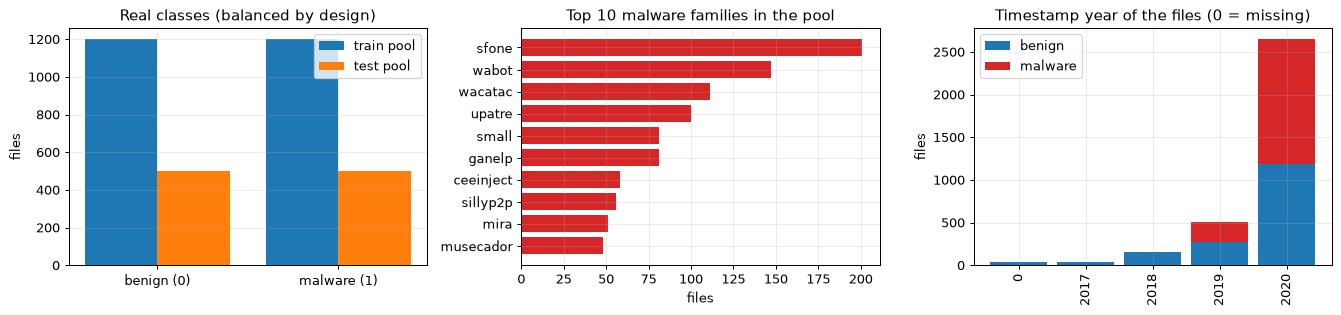

In [8]:
# ---- class distribution of the real files: binary label and malware families
fam_top = list(pd.Series(POOL_FAMILY[Y_ALL == 1]).value_counts().index[:5])
FAM_GROUP = np.where(Y_ALL == 0, "benign", np.where(np.isin(POOL_FAMILY, fam_top), POOL_FAMILY, "other malware"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, (nm, idx) in enumerate([("train pool", TR_ALL), ("test pool", TE_ALL)]):
    c = np.bincount(Y_ALL[idx], minlength=2); ax[0].bar(np.arange(2) + 0.4 * k - 0.2, c, width=0.4, label=nm)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["benign (0)", "malware (1)"]); ax[0].set_ylabel("files"); ax[0].set_title("Real classes (balanced by design)"); ax[0].legend()
topf = pd.Series(POOL_FAMILY[Y_ALL == 1]).value_counts().head(10)
ax[1].barh(topf.index[::-1], topf.values[::-1], color="tab:red"); ax[1].set_title("Top 10 malware families in the pool"); ax[1].set_xlabel("files")
yr = pd.crosstab(POOL_YEAR, Y_ALL); yr.plot(kind="bar", stacked=True, ax=ax[2], color=["tab:blue", "tab:red"], width=0.85)
ax[2].set_title("Timestamp year of the files (0 = missing)"); ax[2].set_xlabel(""); ax[2].legend(["benign", "malware"]); ax[2].set_ylabel("files")
plt.tight_layout(); plt.show()

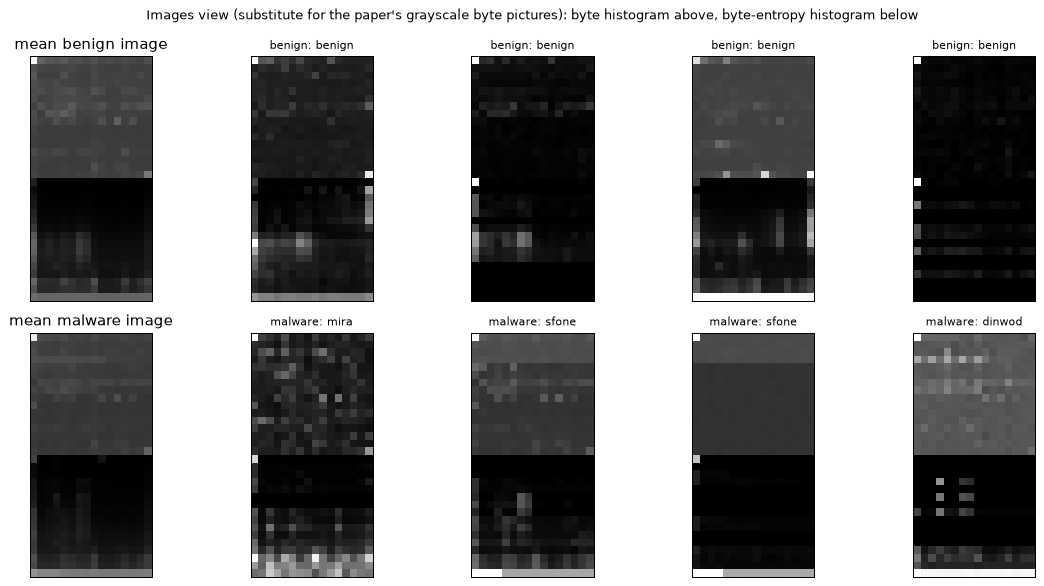

In [9]:
# ---- what the "images" look like: mean picture per class and a few single files (top 16 rows = byte histogram, bottom 16 rows = byte-entropy histogram)
rng_v = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 5, figsize=(13, 6.6))
for r, (cls, nm) in enumerate([(0, "benign"), (1, "malware")]):
    idx = np.flatnonzero(Y_ALL == cls)
    ax[r, 0].imshow(IMAGES[idx].mean(0), cmap="gray", vmin=0, vmax=255); ax[r, 0].set_title(f"mean {nm} image")
    for c, i in enumerate(rng_v.choice(idx, 4, replace=False)):
        ax[r, c + 1].imshow(IMAGES[i], cmap="gray", vmin=0, vmax=255); ax[r, c + 1].set_title(f"{nm}: {POOL_FAMILY[i][:14]}", fontsize=9)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.suptitle("Images view (substitute for the paper's grayscale byte pictures): byte histogram above, byte-entropy histogram below", fontsize=10)
plt.tight_layout(); plt.show()

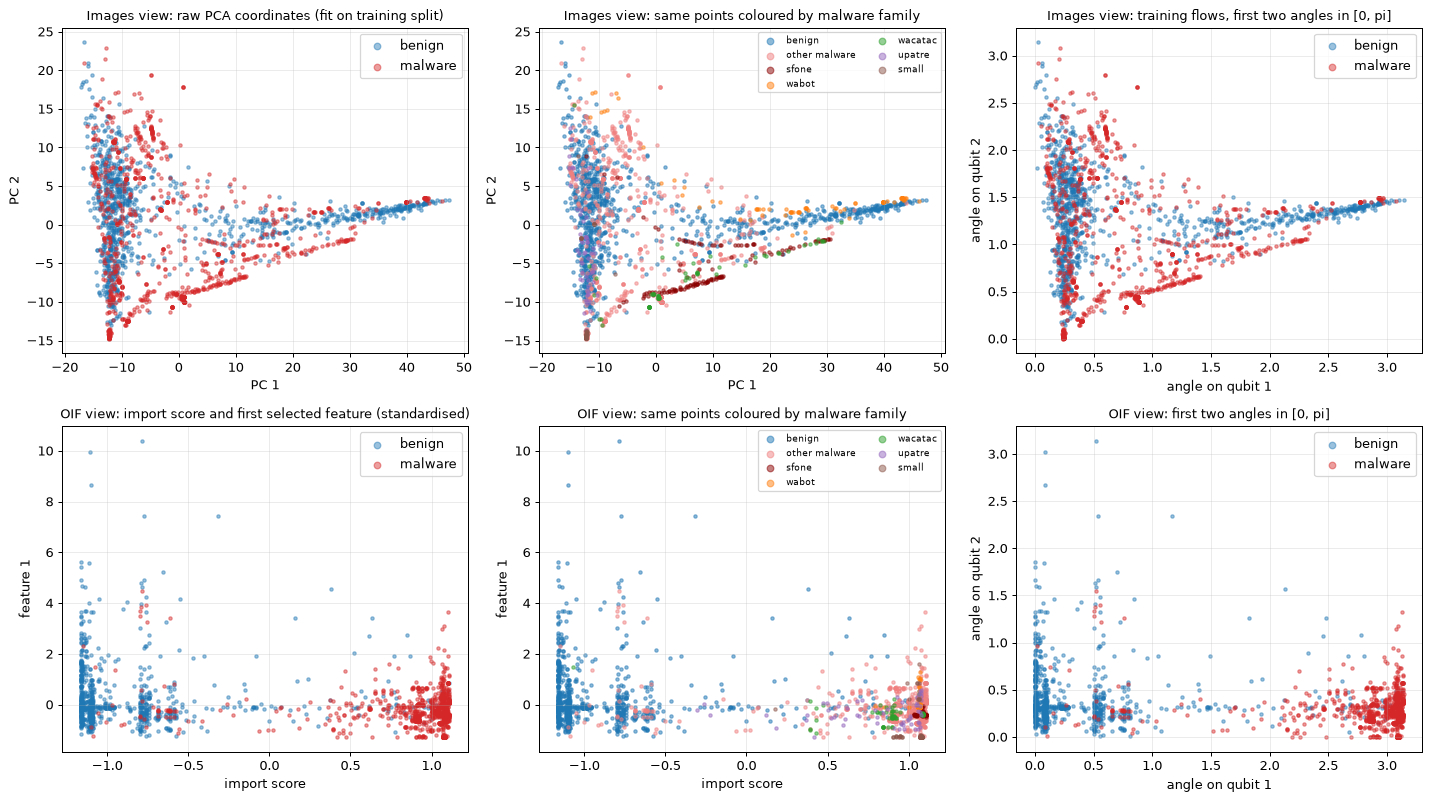

points shown: 2000 real training files ( 1000 benign, 1000 malware ); PCA/scalers fitted on these training rows only


In [10]:
# ---- 2-D scatter of the REAL files, coloured by ground truth.  Transforms fitted on the training split only.
SCAT_TR = TR_ALL[:2000]            # fitted on these training rows
SCAT_SHOW = SCAT_TR            # CHOICE: the plots show training rows (the same rows the transforms are fitted on)
sc_i = StandardScaler().fit(IMG_FLAT[SCAT_TR]); pca_i = PCA(2, random_state=SEED).fit(sc_i.transform(IMG_FLAT[SCAT_TR]))
P_img = pca_i.transform(sc_i.transform(IMG_FLAT[SCAT_SHOW]))
mm_i = MinMaxScaler((0, pi)).fit(pca_i.transform(sc_i.transform(IMG_FLAT[SCAT_TR])))
A_img = np.clip(mm_i.transform(P_img), 0, pi)
sc_o = StandardScaler().fit(OIF_ALL[SCAT_TR][:, :2])
P_oif = sc_o.transform(OIF_ALL[SCAT_SHOW][:, :2])
mm_o = MinMaxScaler((0, pi)).fit(sc_o.transform(OIF_ALL[SCAT_TR][:, :2]))
A_oif = np.clip(mm_o.transform(P_oif), 0, pi)
yS, gS = Y_ALL[SCAT_SHOW], FAM_GROUP[SCAT_SHOW]
palette = {"benign": "tab:blue", "other malware": "lightcoral"}
for f, c in zip(fam_top, ["darkred", "tab:orange", "tab:green", "tab:purple", "tab:brown"]): palette[f] = c

def scat_bin(ax, Z, title, xl, yl):
    for cls, nm, col in [(0, "benign", "tab:blue"), (1, "malware", "tab:red")]:
        m = yS == cls; ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.45, c=col, label=nm)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(markerscale=2)

def scat_fam(ax, Z, title, xl, yl):
    for g in ["benign", "other malware"] + fam_top:
        m = gS == g; ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.5, c=palette[g], label=g[:16])
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(markerscale=2, fontsize=7, ncol=2)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
scat_bin(ax[0, 0], P_img, "Images view: raw PCA coordinates (fit on training split)", "PC 1", "PC 2")
scat_fam(ax[0, 1], P_img, "Images view: same points coloured by malware family", "PC 1", "PC 2")
scat_bin(ax[0, 2], A_img, "Images view: training flows, first two angles in [0, pi]", "angle on qubit 1", "angle on qubit 2")
scat_bin(ax[1, 0], P_oif, "OIF view: import score and first selected feature (standardised)", "import score", "feature 1")
scat_fam(ax[1, 1], P_oif, "OIF view: same points coloured by malware family", "import score", "feature 1")
scat_bin(ax[1, 2], A_oif, "OIF view: first two angles in [0, pi]", "angle on qubit 1", "angle on qubit 2")
plt.tight_layout(); plt.show()
print("points shown:", len(SCAT_SHOW), "real training files (", int((yS == 0).sum()), "benign,", int((yS == 1).sum()), "malware ); PCA/scalers fitted on these training rows only")

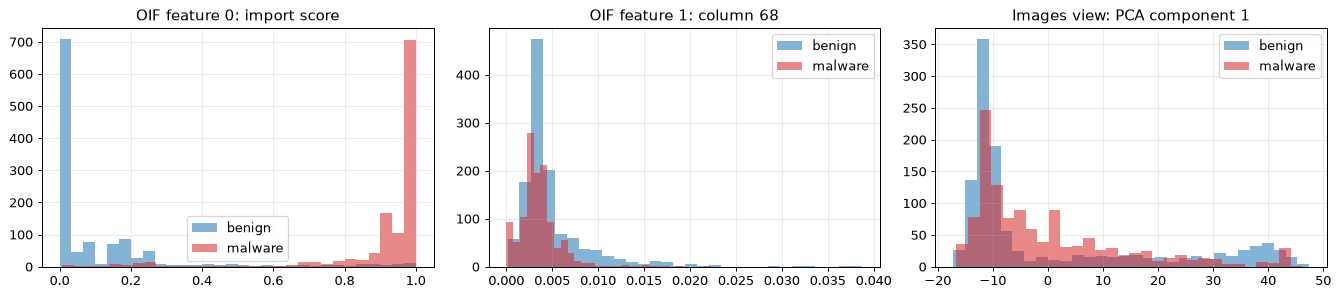

In [11]:
# ---- how separable is each view with ONE feature?  (distribution of the first OIF feature and of the first PCA component per class)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for cls, nm, col in [(0, "benign", "tab:blue"), (1, "malware", "tab:red")]:
    m = Y_ALL[TR_ALL] == cls
    ax[0].hist(OIF_ALL[TR_ALL][m, 0], bins=30, alpha=0.55, color=col, label=nm)
    ax[1].hist(OIF_ALL[TR_ALL][m, 1], bins=30, alpha=0.55, color=col, label=nm)
    ax[2].hist(pca_i.transform(sc_i.transform(IMG_FLAT[TR_ALL]))[m, 0], bins=30, alpha=0.55, color=col, label=nm)
for a, t in zip(ax, ["OIF feature 0: import score", f"OIF feature 1: column {SEL_COLS[0]}", "Images view: PCA component 1"]): a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

This section defines **every quantum circuit that the notebook trains or evaluates**, draws the Qiskit circuit objects, prints qubit count, depth and trainable-parameter count, and proves that the fast NumPy simulators used in the experiments produce exactly the same numbers as Qiskit.

**Why a NumPy simulator?** The QSVM needs the state of up to 20 000 data points for four feature maps, and the QNN needs the output of thousands of circuit evaluations per training run (the parameter-shift rule runs two circuits per trainable parameter for every training file). Executing each of those through `Statevector(circuit)` would take hours. Both circuit families are small and exact, so the notebook uses two vectorised state-vector simulators that apply *the same gates in the same order* as the Qiskit circuits drawn below, and **asserts equality with Qiskit** (`Statevector`, `FidelityStatevectorKernel`, `QSVC`) before using them.

### The QSVM circuits (paper Equations 1 to 4)

The data are encoded with four **feature maps** on `n` qubits (`reps = 2` layers, linear entanglement, as in the paper's Figure 2): `ZZ` (Eq. 1, the data function `phi_j(x) = x_j`, `phi_jk(x) = (pi - x_j)(pi - x_k)`), `Pauli` (Eq. 3, rotations `X`, `Y` and `ZZ`), `ZZphi` (the same circuit as ZZ with `phi_jk(x) = sin(pi - x_j) sin(pi - x_k)`) and `Z` (Eq. 4, no entanglement, classically simulable). The kernel entry of two files is the fidelity `|<phi(x)|phi(y)>|^2`; the circuit that is executed for each file is the feature map applied to `|0...0>`.

### The QNN circuit (paper section 3.1, Figure 3)

`N` data qubits plus **2 ancilla qubits**. State preparation: a Hadamard and the rotation `U(x_j)` on each data qubit, which together give `cos(x_j)|0> + sin(x_j)|1>` for inputs `x_j` in `[0, pi/2]`. Then `L` layers, each: an `RY(theta)` on every data qubit, a chain of CNOT gates that entangles all data and ancilla qubits (the figure is not in the extracted text, so the chain `q0 -> q1 -> ... -> q(N+1)` is a `# CHOICE:`), and on each ancilla a sequence `RY, RZ, RY` of three trainable rotations. The two ancillas are measured in the Z basis; their expectation values are the two logits (class 0 and class 1) of a softmax cross-entropy loss. Trainable parameters: `L (N + 6)`. **Data re-uploading** (section 4.2) repeats the encoding block `H, U(x)` at the start of every layer.

In [12]:
# ============================================================ Qiskit circuits (these objects are what the experiments simulate)
def qnn_circuit(N, L, reupload=False, measure=False):
    """QNN of Barrue and Quertier (after Chalumuri et al.): N data qubits (0..N-1) + 2 ancillas (N, N+1)."""
    x = ParameterVector("x", N)
    th = ParameterVector("θ", L * (N + 6))
    qc = QuantumCircuit(N + 2, 2 if measure else 0)
    def encode():
        for j in range(N):
            qc.h(j); qc.ry(2 * x[j] - pi / 2, j)         # H, then U(x_j) = RY(2 x_j - pi/2): total cos(x_j)|0> + sin(x_j)|1>
    encode()
    k = 0
    for l in range(L):
        if reupload and l > 0:
            encode()                                      # data re-uploading: encode again at the start of every layer
        for j in range(N):
            qc.ry(th[k], j); k += 1
        for q in range(N + 1):
            qc.cx(q, q + 1)                               # CHOICE: CNOT chain entangling all data and ancilla qubits
        for a in (N, N + 1):
            qc.ry(th[k], a); qc.rz(th[k + 1], a); qc.ry(th[k + 2], a); k += 3
        qc.barrier()
    if measure:
        qc.measure(N, 0); qc.measure(N + 1, 1)
    return qc, x, th

def qiskit_fm(n, kind):
    """The four feature maps of the paper (reps = 2, linear entanglement)."""
    if kind == "zz":
        return zz_feature_map(n, reps=2, entanglement="linear")
    if kind == "z":
        return z_feature_map(n, reps=2)
    if kind == "pauli":
        return pauli_feature_map(n, reps=2, paulis=["X", "Y", "ZZ"], entanglement="linear")
    if kind == "zphi":                                    # phi_j = x_j, phi_jk = sin(pi - x_j) sin(pi - x_k)
        def f(x):
            return x[0] if len(x) == 1 else (pi - x[0]).sin() * (pi - x[1]).sin()
        return pauli_feature_map(n, reps=2, paulis=["Z", "ZZ"], entanglement="linear", data_map_func=f)
    raise ValueError(kind)

FM_KINDS = ["zz", "pauli", "zphi", "z"]
FM_LABEL = {"zz": "ZZ", "pauli": "Pauli", "zphi": "ZZphi", "z": "Z"}

In [13]:
# ============================================================ exact NumPy simulators of those circuits
class QNNSim:
    """Exact batched state-vector simulator of qnn_circuit (qubit k = bit k of the basis index)."""
    H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

    def __init__(self, N, L, reupload=False):
        self.N, self.L, self.reupload = N, L, reupload
        self.n, self.W = N + 2, N + 6
        self.P = L * self.W
        idx = np.arange(2 ** self.n)
        v = idx.copy()
        for q in range(N + 1):
            v = v ^ (((v >> q) & 1) << (q + 1))               # the CNOT chain 0->1->...->N+1 as a permutation of the basis
        self.src, self.isrc = np.argsort(v), v                  # forward: new = old[src]; backward: old = new[isrc]
        self.zsign = np.array([[1 - 2 * ((i >> a) & 1) for i in idx] for a in (N, N + 1)], dtype=float)

    @staticmethod
    def ry(t):
        t = np.asarray(t, dtype=float); c, s = np.cos(t / 2), np.sin(t / 2)
        U = np.empty(t.shape + (2, 2), dtype=complex)
        U[..., 0, 0] = c; U[..., 0, 1] = -s; U[..., 1, 0] = s; U[..., 1, 1] = c
        return U

    @staticmethod
    def rz(t):
        t = np.asarray(t, dtype=float)
        U = np.zeros(t.shape + (2, 2), dtype=complex)
        U[..., 0, 0] = np.exp(-0.5j * t); U[..., 1, 1] = np.exp(0.5j * t)
        return U

    def _ap(self, psi, q, U):
        B = psi.shape[0]
        p = psi.reshape(B, 2 ** (self.n - 1 - q), 2, 2 ** q)
        return (U[:, None] @ p if U.ndim == 3 else U @ p).reshape(B, -1)

    def _product_state(self, x):
        B = x.shape[0]
        psi = np.ones((B, 1), dtype=complex)
        for q in range(self.n - 1, -1, -1):
            v = np.stack([np.cos(x[:, q]), np.sin(x[:, q])], 1) if q < self.N else np.tile([1.0, 0.0], (B, 1))
            psi = (psi[:, :, None] * v[:, None, :]).reshape(B, -1)
        return psi

    def expvals(self, theta, x):
        """theta (B,P), x (B,N) -> (B,2): <Z> of the two ancillas.  H then U(x) acting on |0> equals the product state cos x|0> + sin x|1>."""
        B, N = theta.shape[0], self.N
        th = theta.reshape(B, self.L, self.W)
        psi = self._product_state(x)
        if self.reupload:
            E = [self.ry(2 * x[:, j] - pi / 2) @ self.H for j in range(N)]
        for l in range(self.L):
            if l > 0 and self.reupload:
                for j in range(N): psi = self._ap(psi, j, E[j])
            R = self.ry(th[:, l, :N])
            for j in range(N): psi = self._ap(psi, j, R[:, j])
            psi = psi[:, self.src]
            for a in range(2):
                k = N + 3 * a
                A = self.ry(th[:, l, k + 2]) @ self.rz(th[:, l, k + 1]) @ self.ry(th[:, l, k])
                psi = self._ap(psi, N + a, A)
        return (psi.real ** 2 + psi.imag ** 2) @ self.zsign.T

    def value_and_grad(self, theta, x1, g_fn):
        """One sample.  Returns e (2,) and the gradient of  g . e  with g = g_fn(e).  The gradient is computed with the adjoint method; for
        exact expectation values it is identical to the parameter-shift rule (asserted below against explicit +-pi/2 shifts)."""
        N, L, W = self.N, self.L, self.W
        th = theta.reshape(L, W); x1 = x1.reshape(1, N)
        psi = self._product_state(x1)
        E = [(self.ry(2 * x1[:, j] - pi / 2) @ self.H)[0] for j in range(N)] if self.reupload else None
        tape = []                                       # (kind, qubit, first parameter index, state before the gate, matrices)
        for l in range(L):
            if l > 0 and self.reupload:
                for j in range(N):
                    tape.append(("fix", j, -1, None, E[j])); psi = self._ap(psi, j, E[j])
            for j in range(N):
                U = self.ry(th[l, j]); tape.append(("ry", j, l * W + j, psi, U)); psi = self._ap(psi, j, U)
            tape.append(("cx", -1, -1, None, None)); psi = psi[:, self.src]
            for a in range(2):
                k = N + 3 * a
                Ra, Zb, Rc = self.ry(th[l, k]), self.rz(th[l, k + 1]), self.ry(th[l, k + 2])
                A = Rc @ Zb @ Ra; tape.append(("anc", N + a, l * W + k, psi, (Ra, Zb, Rc, A))); psi = self._ap(psi, N + a, A)
        e = ((psi.real ** 2 + psi.imag ** 2) @ self.zsign.T)[0]
        g = g_fn(e)
        lam = psi * (g @ self.zsign)[None]
        grad = np.zeros(self.P)
        for kind, q, k, before, M in reversed(tape):
            if kind == "cx":
                lam = lam[:, self.isrc]; continue
            if kind == "fix":
                lam = self._ap(lam, q, M.conj().T); continue
            a_, c_ = 2 ** (self.n - 1 - q), 2 ** q
            T = np.einsum("aic,ajc->ij", lam.reshape(a_, 2, c_).conj(), before.reshape(a_, 2, c_))
            if kind == "ry":
                dU = 0.5 * self.ry(th.flat[k] + pi)
                grad[k] = 2 * np.real(np.sum(dU * T)); lam = self._ap(lam, q, M.conj().T)
            else:
                Ra, Zb, Rc, A = M; b = th.flat[k + 1]
                dRa, dRc = 0.5 * self.ry(th.flat[k] + pi), 0.5 * self.ry(th.flat[k + 2] + pi)
                dZb = np.array([[-0.5j * np.exp(-0.5j * b), 0], [0, 0.5j * np.exp(0.5j * b)]])
                grad[k] = 2 * np.real(np.sum((Rc @ Zb @ dRa) * T))
                grad[k + 1] = 2 * np.real(np.sum((Rc @ dZb @ Ra) * T))
                grad[k + 2] = 2 * np.real(np.sum((dRc @ Zb @ Ra) * T))
                lam = self._ap(lam, q, A.conj().T)
        return e, grad


class FMSim:
    """Exact state-vector simulator of the four Qiskit feature maps (reps = 2, linear entanglement)."""
    def __init__(self, n, kind, reps=2):
        self.n, self.kind, self.reps = n, kind, reps
        self.paulis = {"zz": ["Z", "ZZ"], "zphi": ["Z", "ZZ"], "pauli": ["X", "Y", "ZZ"], "z": ["Z"]}[kind]
        idx = np.arange(2 ** n)
        self.zs = 1 - 2 * ((idx[None, :] >> np.arange(n)[:, None]) & 1).astype(float)          # (n, 2^n) eigenvalues of Z_j
        self.pairs = [(i, i + 1) for i in range(n - 1)]
        self.zzs = np.array([self.zs[i] * self.zs[j] for i, j in self.pairs]) if self.pairs else np.zeros((0, 2 ** n))
        H = np.array([[1, 1], [1, -1]]) / np.sqrt(2); Hn = np.array([[1.0]])
        for _ in range(n): Hn = np.kron(H, Hn)
        self.Hn = Hn

    def phi2(self, X):
        a, b = X[:, [i for i, _ in self.pairs]], X[:, [j for _, j in self.pairs]]
        return np.sin(pi - a) * np.sin(pi - b) if self.kind == "zphi" else (pi - a) * (pi - b)

    def states(self, X):
        X = np.asarray(X, float); B, n = X.shape
        psi = np.zeros((B, 2 ** n), dtype=complex); psi[:, 0] = 1
        p2 = self.phi2(X) if self.pairs else None
        for _ in range(self.reps):
            psi = psi @ self.Hn.T
            for P in self.paulis:
                if P == "Z":
                    psi = psi * np.exp(-1j * (X @ self.zs))
                elif P == "ZZ":
                    psi = psi * np.exp(-1j * (p2 @ self.zzs))
                else:
                    c, s = np.cos(X), np.sin(X)
                    for j in range(n):
                        U = np.zeros((B, 2, 2), dtype=complex); U[:, 0, 0] = c[:, j]; U[:, 1, 1] = c[:, j]
                        if P == "X": U[:, 0, 1] = -1j * s[:, j]; U[:, 1, 0] = -1j * s[:, j]
                        else: U[:, 0, 1] = -s[:, j]; U[:, 1, 0] = s[:, j]
                        psi = (U[:, None] @ psi.reshape(B, 2 ** (n - 1 - j), 2, 2 ** j)).reshape(B, -1)
        return psi

In [14]:
# ============================================================ equivalence assertions: simulators == Qiskit
rng_t = np.random.default_rng(SEED)
def softmax_grad(e, label=1):
    p = np.exp(e - e.max()); p /= p.sum(); p[label] -= 1; return p        # d(cross-entropy)/d(logits)

rows = []
for (N, L, re) in [(4, 2, False), (4, 3, True), (3, 1, False), (7, 2, False), (7, 2, True)]:
    sim = QNNSim(N, L, re); qc, xv, tv = qnn_circuit(N, L, re)
    th = rng_t.uniform(-pi, pi, (3, sim.P)); x = rng_t.uniform(0, pi / 2, (3, N))
    mine = sim.expvals(th, x); ref = np.zeros((3, 2))
    for b in range(3):
        sv = Statevector(qc.assign_parameters(dict(zip(list(xv) + list(tv), list(x[b]) + list(th[b])))))
        for a, anc in enumerate((N, N + 1)):
            ref[b, a] = sv.expectation_value(SparsePauliOp("I" * (sim.n - 1 - anc) + "Z" + "I" * anc)).real
    d_qiskit = np.abs(mine - ref).max()
    # parameter-shift: explicit +-pi/2 shifted circuit evaluations of the simulator vs the adjoint gradient used for training
    e, gr = sim.value_and_grad(th[0], x[0], softmax_grad)
    S = np.tile(th[0], (2 * sim.P, 1))
    for k in range(sim.P):
        S[2 * k, k] += pi / 2; S[2 * k + 1, k] -= pi / 2
    ev = sim.expvals(S, np.repeat(x[:1], 2 * sim.P, 0)); J = (ev[0::2] - ev[1::2]) / 2
    d_ps = np.abs(gr - J @ softmax_grad(e)).max()
    assert d_qiskit < 1e-10 and d_ps < 1e-10, (N, L, re, d_qiskit, d_ps)
    rows.append((f"QNN N={N} L={L} reupload={re}", d_qiskit, d_ps))
for n in (3, 4, 7):
    for kind in FM_KINDS:
        fm = qiskit_fm(n, kind); X = rng_t.uniform(0, pi, (5, n)); mine = FMSim(n, kind).states(X)
        ref = np.array([Statevector(fm.assign_parameters(dict(zip(fm.parameters, x)))).data for x in X])
        fid = np.abs(np.sum(mine.conj() * ref, 1)) ** 2
        assert fid.min() > 1 - 1e-10, (n, kind, fid.min())
        rows.append((f"feature map {FM_LABEL[kind]} n={n}", 1 - fid.min(), np.nan))
print(pd.DataFrame(rows, columns=["circuit", "max |difference to Qiskit|", "max |adjoint - parameter shift|"]).to_string(index=False))
print("All simulators agree with Qiskit to machine precision (assertions passed).")

                   circuit  max |difference to Qiskit|  max |adjoint - parameter shift|
QNN N=4 L=2 reupload=False                2.081668e-16                     1.665335e-16
 QNN N=4 L=3 reupload=True                4.996004e-16                     1.873501e-16
QNN N=3 L=1 reupload=False                1.942890e-16                     9.714451e-17
QNN N=7 L=2 reupload=False                1.776357e-15                     3.330669e-16
 QNN N=7 L=2 reupload=True                2.324529e-16                     2.775558e-16
        feature map ZZ n=3                2.220446e-15                              NaN
     feature map Pauli n=3                4.662937e-15                              NaN
     feature map ZZphi n=3                2.442491e-15                              NaN
         feature map Z n=3                2.442491e-15                              NaN
        feature map ZZ n=4                3.552714e-15                              NaN
     feature map Pauli n=4      

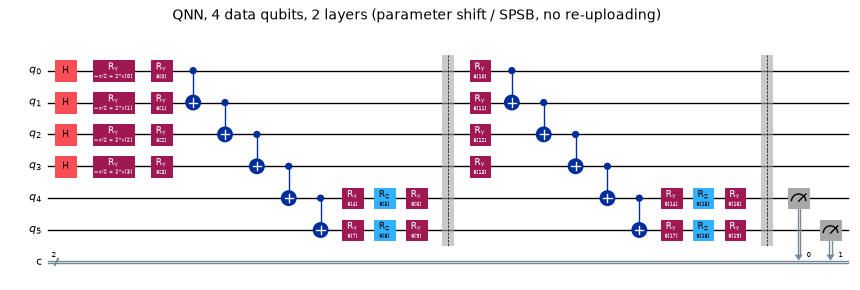

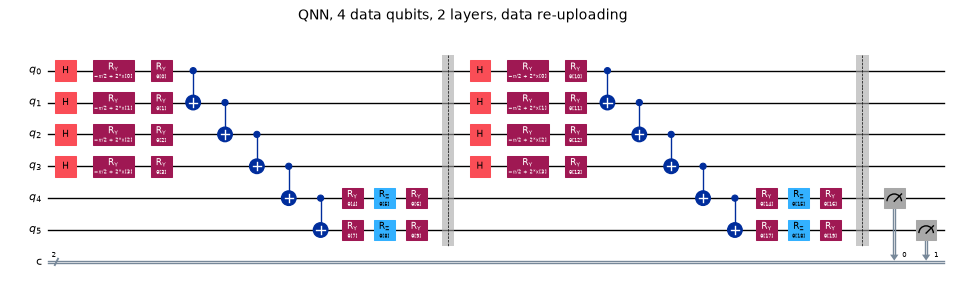

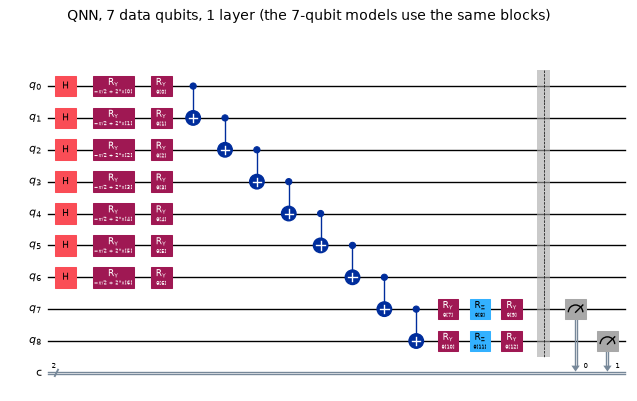

Measured quantities (circuit without the final measurements; trainable = L (N + 6); the N inputs x are data, not trainable)


In [15]:
# ============================================================ drawings of the executed circuits (QNN)
def counts(qc):
    return dict(qubits=qc.num_qubits, depth=qc.depth(), gates=sum(qc.count_ops().values()) - qc.count_ops().get("barrier", 0), parameters=qc.num_parameters)

QNN_DRAW = [("QNN, 4 data qubits, 2 layers (parameter shift / SPSB, no re-uploading)", 4, 2, False),
            ("QNN, 4 data qubits, 2 layers, data re-uploading", 4, 2, True),
            ("QNN, 7 data qubits, 1 layer (the 7-qubit models use the same blocks)", 7, 1, False)]
arch_rows = []
for title, N, L, re in QNN_DRAW:
    qc, xv, tv = qnn_circuit(N, L, re, measure=True)
    fig = qc.draw("mpl", fold=-1, scale=0.55); fig.suptitle(title, fontsize=11, y=1.0); display(fig); plt.close(fig)
    base, _, _ = qnn_circuit(N, L, re)
    arch_rows.append((title, *counts(base).values(), L * (N + 6)))
print("Measured quantities (circuit without the final measurements; trainable = L (N + 6); the N inputs x are data, not trainable)")

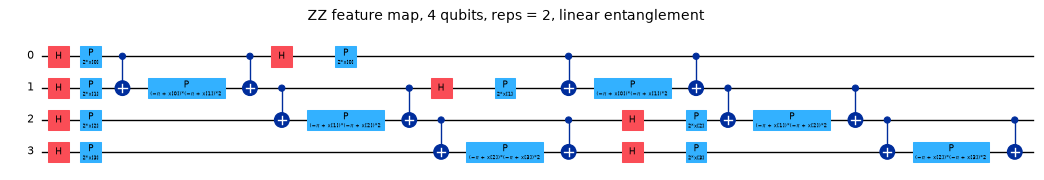

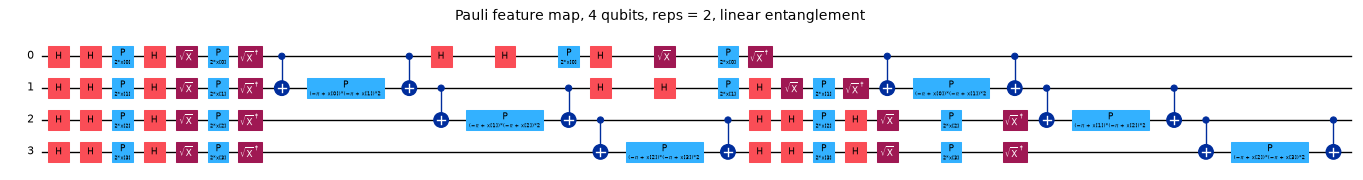

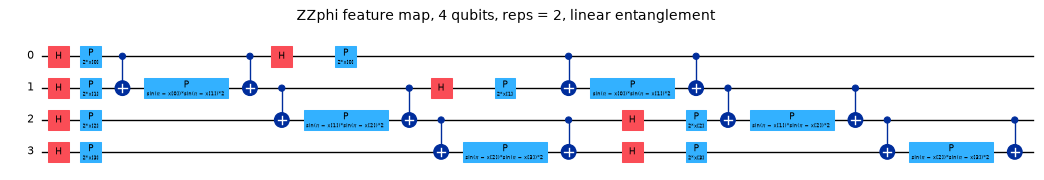

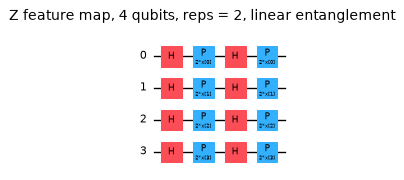

,architecture,qubits,depth (as built),gates,free symbols (inputs x and weights),trainable parameters
0,"QNN, 4 data qubits, 2 layers (parameter shift ...",6,20,38,24,20
1,"QNN, 4 data qubits, 2 layers, data re-uploading",6,22,46,24,20
2,"QNN, 7 data qubits, 1 layer (the 7-qubit model...",9,14,35,20,13
3,"ZZ feature map (4 qubits, reps 2)",4,19,34,4,0
4,"Pauli feature map (4 qubits, reps 2)",4,29,74,4,0
5,"ZZphi feature map (4 qubits, reps 2)",4,19,34,4,0
6,"Z feature map (4 qubits, reps 2)",4,4,16,4,0
7,"ZZ feature map (3 qubits, reps 2)",3,16,24,3,0
8,"Pauli feature map (3 qubits, reps 2)",3,26,54,3,0
9,"ZZphi feature map (3 qubits, reps 2)",3,16,24,3,0


In [16]:
# ============================================================ drawings of the executed circuits (QSVM feature maps, 4 qubits)
for kind in FM_KINDS:
    fm = qiskit_fm(4, kind)
    fig = fm.draw("mpl", fold=-1, scale=0.55); fig.suptitle(f"{FM_LABEL[kind]} feature map, 4 qubits, reps = 2, linear entanglement", fontsize=11, y=1.0)
    display(fig); plt.close(fig)
    arch_rows.append((f"{FM_LABEL[kind]} feature map (4 qubits, reps 2)", *counts(fm).values(), 0))
for n in (3, 6, 7):
    for kind in FM_KINDS:
        fm = qiskit_fm(n, kind); arch_rows.append((f"{FM_LABEL[kind]} feature map ({n} qubits, reps 2)", *counts(fm).values(), 0))
ARCH = pd.DataFrame(arch_rows, columns=["architecture", "qubits", "depth (as built)", "gates", "free symbols (inputs x and weights)", "trainable parameters"])
display(ARCH)

## 2. Quantum Support Vector Machine (paper section 2, Tables 3 to 11)

**The idea in plain words.** A support vector machine separates two classes by a boundary that only depends on the **kernel** `K(x, y)`, a similarity score between two files. A *quantum kernel* defines that score as the overlap of two quantum states, `K(x, y) = |<phi(x)|phi(y)>|^2`, where `|phi(x)>` is the state a feature-map circuit prepares from the file's `n` numbers. The SVM itself stays classical (`SVC(kernel="precomputed")`, `C = 1`); only the kernel matrix comes from the circuits. The number of qubits equals the number of input features (after PCA for the Images view, the first `n` ordered features for the OIF view).

**Protocol of the paper.** Balanced random samples of `train/test` files (500/100, 1000/200, ..., 16000/4000), 4 qubits by default, then 3, 4, 6, 7 qubits; four quantum feature maps against four classical kernels (linear, polynomial, RBF, sigmoid, scikit-learn defaults); accuracy and F1 score (malware = positive class).

**What this notebook adds around it** (see the `# CHOICE:` comments): all transforms are fitted on the training files only (`StandardScaler` -> `PCA(n)` -> `MinMaxScaler((0, pi))`, test angles clipped to `[0, pi]`); the **kernel bandwidth** (an overall scale of the angles, `BW_GRID`) is chosen on a validation split of the training files, never on the test files; for sizes up to 2 000 files the draw is repeated `REPS` times and reported as mean (std); two extra classical baselines are trained on the same angles: an **RBF SVM with `C` and `gamma` tuned on the same validation split** and a **random forest**.

In [17]:
def prep(view, tr, te, k, hi):
    """Fit every transform on the training rows only.  Returns raw coordinates and angles in [0, hi] (test angles clipped)."""
    if view == "img":
        sc = StandardScaler().fit(IMG_FLAT[tr]); pca = PCA(k, random_state=SEED).fit(sc.transform(IMG_FLAT[tr]))
        f = lambda i: pca.transform(sc.transform(IMG_FLAT[i]))
    else:                                                       # OIF: the first k ordered features, no PCA
        sc = StandardScaler().fit(OIF_ALL[tr][:, :k]); f = lambda i: sc.transform(OIF_ALL[i][:, :k])
    Ztr, Zte = f(tr), f(te)
    mm = MinMaxScaler((0, hi)).fit(Ztr)
    return Ztr, Zte, mm.transform(Ztr), np.clip(mm.transform(Zte), 0, hi)

def draw_sample(n_tr, n_te, rep):
    """Class-balanced random sample of n_tr training and n_te test files from the pools."""
    rng = np.random.default_rng(SEED + 1000 * rep + n_tr)
    def bal(pool, m):
        neg, pos = pool[Y_ALL[pool] == 0], pool[Y_ALL[pool] == 1]
        return rng.permutation(np.concatenate([rng.choice(neg, m // 2, replace=False), rng.choice(pos, m // 2, replace=False)]))
    return bal(TR_ALL, n_tr), bal(TE_ALL, n_te)

def gram(S1, S2, chunk=2048):
    """|<s1|s2>|^2 for all pairs, in float32 (chunked, so 16 000 x 16 000 fits in memory)."""
    S2h = np.ascontiguousarray(S2.conj().T).astype(np.complex64); S1c = S1.astype(np.complex64)
    out = np.empty((len(S1), len(S2)), dtype=np.float32)
    for a in range(0, len(S1), chunk):
        M = S1c[a:a + chunk] @ S2h
        out[a:a + chunk] = M.real ** 2 + M.imag ** 2
    return out

def metrics(y, p):
    return dict(acc=accuracy_score(y, p), f1=f1_score(y, p, pos_label=1), prec=precision_score(y, p, pos_label=1, zero_division=0),
                rec=recall_score(y, p, pos_label=1, zero_division=0))

def tune_bw(kind, k, Atr, ytr):
    """Angle scale chosen on a validation split of the training data (CHOICE: 75/25 split of at most 800 training files)."""
    m = min(len(Atr), 800)
    a, b = train_test_split(np.arange(m), test_size=0.25, stratify=ytr[:m], random_state=SEED)
    fm = FMSim(k, kind); best_acc, best_s = -1, BW_GRID[-1]
    for s in BW_GRID:
        S = fm.states(Atr[:m] * s)
        acc = SVC(kernel="precomputed", C=SVM_C).fit(gram(S[a], S[a]), ytr[a]).score(gram(S[b], S[a]), ytr[b])
        if acc >= best_acc: best_acc, best_s = acc, s
    return best_s

def tuned_rbf(Atr, ytr, Ate):
    m = min(len(Atr), 800)
    a, b = train_test_split(np.arange(m), test_size=0.25, stratify=ytr[:m], random_state=SEED)
    g0 = 1.0 / (Atr.shape[1] * Atr.var()); best = (-1, 1.0, g0)
    for C in (1.0, 10.0, 100.0):
        for g in (0.3 * g0, g0, 3 * g0):
            acc = SVC(kernel="rbf", C=C, gamma=g).fit(Atr[a], ytr[a]).score(Atr[b], ytr[b])
            if acc > best[0]: best = (acc, C, g)
    return SVC(kernel="rbf", C=best[1], gamma=best[2]).fit(Atr, ytr).predict(Ate)

def run_cell(view, k, n_tr, n_te, rep):
    """One (view, qubits, sizes, repetition) cell: 4 quantum kernels + 4 classical SVMs + tuned RBF + random forest on identical angles."""
    tr, te = draw_sample(n_tr, n_te, rep)
    Ztr, Zte, Atr, Ate = prep(view, tr, te, k, pi)
    ytr, yte = Y_ALL[tr], Y_ALL[te]
    rows = []
    for kind in FM_KINDS:
        t0 = time.time(); s = tune_bw(kind, k, Atr, ytr); fm = FMSim(k, kind)
        Str, Ste = fm.states(Atr * s), fm.states(Ate * s)
        clf = SVC(kernel="precomputed", C=SVM_C).fit(gram(Str, Str), ytr)
        rows.append(dict(model="QSVM " + FM_LABEL[kind], bw=s, time=time.time() - t0, **metrics(yte, clf.predict(gram(Ste, Str)))))
    for kn in ("linear", "poly", "rbf", "sigmoid"):
        t0 = time.time(); clf = SVC(kernel=kn, C=SVM_C).fit(Atr, ytr)
        rows.append(dict(model=kn, bw=np.nan, time=time.time() - t0, **metrics(yte, clf.predict(Ate))))
    t0 = time.time(); rows.append(dict(model="rbf (tuned C, gamma)", bw=np.nan, time=0, **metrics(yte, tuned_rbf(Atr, ytr, Ate))))
    t0 = time.time(); rf = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(Atr, ytr)
    rows.append(dict(model="random forest", bw=np.nan, time=time.time() - t0, **metrics(yte, rf.predict(Ate))))
    for r in rows: r.update(view=view, qubits=k, n_train=n_tr, n_test=n_te, rep=rep)
    return rows

QSVM_ROWS = []; QSVM_DONE = set()
def run_exp(view, k, n_tr, n_te):
    key = (view, k, n_tr, n_te)
    if key in QSVM_DONE: return
    reps = REPS if n_tr <= 2000 else 1
    t0 = time.time()
    for r in range(reps): QSVM_ROWS.extend(run_cell(view, k, n_tr, n_te, r))
    QSVM_DONE.add(key); print(f"  {view:3s} qubits={k} {n_tr:6d}/{n_te:5d}  reps={reps}  {time.time() - t0:6.1f} s", flush=True)

In [18]:
# ---- Check 1: our kernel and our SVM equal Qiskit's FidelityStatevectorKernel + QSVC (small real example, 4 qubits)
tr_c, te_c = draw_sample(80, 40, 99)
_, _, Atr_c, Ate_c = prep("img", tr_c, te_c, 4, pi)
rows = []
for kind in FM_KINDS:
    fmq = qiskit_fm(4, kind)
    qk = FidelityStatevectorKernel(feature_map=fmq)
    K_q = qk.evaluate(Atr_c[:20], Atr_c[:20])
    S = FMSim(4, kind).states(Atr_c[:20]); K_m = np.abs(S.conj() @ S.T) ** 2
    qsvc = QSVC(quantum_kernel=qk, C=SVM_C).fit(Atr_c, Y_ALL[tr_c]); p_q = qsvc.predict(Ate_c)
    Str, Ste = FMSim(4, kind).states(Atr_c), FMSim(4, kind).states(Ate_c)
    p_m = SVC(kernel="precomputed", C=SVM_C).fit(np.abs(Str.conj() @ Str.T) ** 2, Y_ALL[tr_c]).predict(np.abs(Ste.conj() @ Str.T) ** 2)
    assert np.allclose(K_q, K_m, atol=1e-10) and (p_q == p_m).all(), kind
    rows.append((FM_LABEL[kind], np.abs(K_q - K_m).max(), float((p_q == p_m).mean()), accuracy_score(Y_ALL[te_c], p_q)))
print(pd.DataFrame(rows, columns=["feature map", "max |K_qiskit - K_numpy|", "same predictions (QSVC vs SVC precomputed)", "test accuracy of both (40 files)"]).to_string(index=False))

feature map  max |K_qiskit - K_numpy|  same predictions (QSVC vs SVC precomputed)  test accuracy of both (40 files)
         ZZ              3.330669e-15                                         1.0                             0.775
      Pauli              5.329071e-15                                         1.0                             0.625
      ZZphi              3.774758e-15                                         1.0                             0.700
          Z              3.330669e-15                                         1.0                             0.725


In [19]:
# ---- Experiment A: Tables 3 and 4 (and 8, 9 for OIF): growing training sets at the default number of qubits
t_exp = time.time()
print(f"Experiment A: sizes {QSVM_SIZES}, {QSVM_QUBITS} qubits")
for view in ("img", "oif"):
    for (n_tr, n_te) in QSVM_SIZES:
        run_exp(view, QSVM_QUBITS, n_tr, n_te)
print(f"experiment A done in {time.time() - t_exp:.0f} s")

Experiment A: sizes [(500, 100), (1000, 200), (2000, 400)], 4 qubits


  img qubits=4    500/  100  reps=2    24.8 s


  img qubits=4   1000/  200  reps=2    28.5 s


  img qubits=4   2000/  400  reps=2    63.1 s


  oif qubits=4    500/  100  reps=2    23.2 s


  oif qubits=4   1000/  200  reps=2    26.7 s


  oif qubits=4   2000/  400  reps=2    33.2 s


experiment A done in 199 s


In [20]:
# ---- Experiment B: Tables 5, 6 (Images) and 10, 11 (OIF): 3, 4, 6, 7 qubits
t_exp = time.time()
print(f"Experiment B: qubit sweep {QUBIT_SWEEP}")
for view in ("img", "oif"):
    for k, (n_tr, n_te) in QUBIT_SWEEP.items():
        run_exp(view, k, n_tr, n_te)
QSVM = pd.DataFrame(QSVM_ROWS)
print(f"experiment B done in {time.time() - t_exp:.0f} s; {len(QSVM)} result rows")

Experiment B: qubit sweep {3: (1000, 200), 4: (1000, 200), 6: (1000, 200), 7: (1000, 200)}


  img qubits=3   1000/  200  reps=2    32.1 s


  img qubits=6   1000/  200  reps=2    39.8 s


  img qubits=7   1000/  200  reps=2    37.8 s


  oif qubits=3   1000/  200  reps=2    14.5 s


  oif qubits=6   1000/  200  reps=2    15.3 s


  oif qubits=7   1000/  200  reps=2    31.5 s


experiment B done in 171 s; 240 result rows


In [21]:
# ---- paper-style tables (mean over repetitions, std in brackets for the repeated sizes)
QSVM_AGG = QSVM.groupby(["view", "qubits", "n_train", "n_test", "model"]).agg(acc=("acc", "mean"), acc_std=("acc", "std"), f1=("f1", "mean"), f1_std=("f1", "std"),
                                                                              time=("time", "mean"), n=("acc", "size")).reset_index()
QSVM_AGG[["acc_std", "f1_std"]] = QSVM_AGG[["acc_std", "f1_std"]].fillna(0.0)
def fmt(m, s): return f"{m:.3f}" + (f" ({s:.3f})" if s > 0 else "")
def table(view, models, metric="acc", k=QSVM_QUBITS, by="size", sweep=None):
    d = QSVM_AGG[QSVM_AGG.view == view]
    if by == "size":
        d = d[d.qubits == k]; idx = [(a, b) for a, b in QSVM_SIZES]; lab = lambda i: f"{i[0]}/{i[1]}"
        get = lambda i, m: d[(d.n_train == i[0]) & (d.n_test == i[1]) & (d.model == m)]
    else:
        idx = list(QUBIT_SWEEP.items()); lab = lambda i: f"{i[0]} qubits ({i[1][0]}/{i[1][1]})"
        get = lambda i, m: d[(d.qubits == i[0]) & (d.n_train == i[1][0]) & (d.n_test == i[1][1]) & (d.model == m)]
    out = {}
    for m in models:
        out[m] = [fmt(get(i, m)[metric].iloc[0], get(i, m)[metric + "_std"].iloc[0]) for i in idx]
    return pd.DataFrame(out, index=[lab(i) for i in idx])
QM = ["QSVM " + FM_LABEL[k] for k in FM_KINDS]; CM = ["linear", "poly", "rbf", "sigmoid"]
print("=== Images view, Table 3 analogue: accuracy of the ZZ QSVM against four classical SVMs (+ extra baselines), 4 qubits ===")
display(table("img", ["QSVM ZZ"] + CM + ["rbf (tuned C, gamma)", "random forest"]))
print("F1 score of the ZZ QSVM:"); display(table("img", ["QSVM ZZ"], "f1"))
print("=== Images view, Table 4 analogue: accuracy of the four feature maps ===")
display(table("img", QM))
print("=== Images view, Table 5 analogue: accuracy for 3, 4, 6, 7 qubits (PCA components) ===")
display(table("img", QM + CM + ["rbf (tuned C, gamma)", "random forest"], by="sweep"))
print("=== Images view, Table 6 analogue: F1 for 3, 4, 6, 7 qubits ===")
display(table("img", QM, "f1", by="sweep"))

=== Images view, Table 3 analogue: accuracy of the ZZ QSVM against four classical SVMs (+ extra baselines), 4 qubits ===


,QSVM ZZ,linear,poly,rbf,sigmoid,"rbf (tuned C, gamma)",random forest
500/100,0.725 (0.035),0.705 (0.021),0.745 (0.007),0.720,0.315 (0.021),0.765 (0.007),0.770 (0.057)
1000/200,0.792 (0.032),0.680 (0.007),0.760 (0.007),0.780 (0.014),0.330,0.865 (0.007),0.853 (0.004)
2000/400,0.752 (0.039),0.644 (0.002),0.728 (0.018),0.738 (0.025),0.360 (0.004),0.804 (0.030),0.877 (0.007)


F1 score of the ZZ QSVM:


,QSVM ZZ
500/100,0.681 (0.093)
1000/200,0.776 (0.040)
2000/400,0.721 (0.049)


=== Images view, Table 4 analogue: accuracy of the four feature maps ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z
500/100,0.725 (0.035),0.720 (0.028),0.755 (0.007),0.760 (0.028)
1000/200,0.792 (0.032),0.778 (0.004),0.802 (0.032),0.788 (0.011)
2000/400,0.752 (0.039),0.746 (0.009),0.789 (0.016),0.758 (0.011)


=== Images view, Table 5 analogue: accuracy for 3, 4, 6, 7 qubits (PCA components) ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z,linear,poly,rbf,sigmoid,"rbf (tuned C, gamma)",random forest
3 qubits (1000/200),0.745 (0.007),0.742 (0.025),0.742 (0.004),0.748 (0.025),0.630,0.675 (0.042),0.750 (0.035),0.625,0.790,0.815 (0.021)
4 qubits (1000/200),0.792 (0.032),0.778 (0.004),0.802 (0.032),0.788 (0.011),0.680 (0.007),0.760 (0.007),0.780 (0.014),0.330,0.865 (0.007),0.853 (0.004)
6 qubits (1000/200),0.860 (0.021),0.812 (0.004),0.840,0.825 (0.007),0.742 (0.025),0.810 (0.028),0.790 (0.042),0.275 (0.007),0.873 (0.025),0.885
7 qubits (1000/200),0.867 (0.025),0.833 (0.004),0.853 (0.004),0.837 (0.004),0.735 (0.014),0.812 (0.039),0.818 (0.025),0.312 (0.060),0.885 (0.014),0.880 (0.021)


=== Images view, Table 6 analogue: F1 for 3, 4, 6, 7 qubits ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z
3 qubits (1000/200),0.724 (0.018),0.708 (0.027),0.706 (0.012),0.717 (0.015)
4 qubits (1000/200),0.776 (0.040),0.748 (0.001),0.786 (0.043),0.764 (0.020)
6 qubits (1000/200),0.853 (0.024),0.803 (0.001),0.827 (0.001),0.806 (0.012)
7 qubits (1000/200),0.860 (0.020),0.821 (0.002),0.838 (0.005),0.820 (0.000)


In [22]:
print("=== OIF view, Table 8 analogue (paper table not recoverable from the PDF text): accuracy, 4 qubits ===")
display(table("oif", QM + CM + ["rbf (tuned C, gamma)", "random forest"]))
print("=== OIF view, Table 9 analogue: F1 of the four QSVMs ===")
display(table("oif", QM, "f1"))
print("=== OIF view, Table 10 analogue: accuracy for 3, 4, 6, 7 qubits (first n ordered features) ===")
display(table("oif", QM + CM + ["rbf (tuned C, gamma)", "random forest"], by="sweep"))
print("=== OIF view, Table 11 analogue: F1 for 3, 4, 6, 7 qubits ===")
display(table("oif", QM, "f1", by="sweep"))

=== OIF view, Table 8 analogue (paper table not recoverable from the PDF text): accuracy, 4 qubits ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z,linear,poly,rbf,sigmoid,"rbf (tuned C, gamma)",random forest
500/100,0.965 (0.007),0.930 (0.028),0.970,0.970,0.970,0.970,0.960,0.870 (0.042),0.970,0.965 (0.007)
1000/200,0.945 (0.007),0.940 (0.021),0.950 (0.007),0.950 (0.007),0.950 (0.007),0.945 (0.014),0.952 (0.004),0.883 (0.032),0.952 (0.004),0.965 (0.007)
2000/400,0.948,0.946 (0.002),0.945 (0.004),0.944 (0.005),0.944 (0.005),0.941 (0.002),0.944 (0.005),0.880 (0.067),0.942 (0.004),0.965 (0.007)


=== OIF view, Table 9 analogue: F1 of the four QSVMs ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z
500/100,0.965 (0.006),0.932 (0.026),0.970 (0.000),0.970 (0.000)
1000/200,0.945 (0.006),0.939 (0.021),0.950 (0.006),0.950 (0.007)
2000/400,0.947 (0.001),0.946 (0.002),0.945 (0.004),0.943 (0.006)


=== OIF view, Table 10 analogue: accuracy for 3, 4, 6, 7 qubits (first n ordered features) ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z,linear,poly,rbf,sigmoid,"rbf (tuned C, gamma)",random forest
3 qubits (1000/200),0.940 (0.014),0.938 (0.011),0.948 (0.011),0.950 (0.007),0.950 (0.007),0.945 (0.014),0.952 (0.004),0.637 (0.039),0.955,0.958 (0.004)
4 qubits (1000/200),0.945 (0.007),0.940 (0.021),0.950 (0.007),0.950 (0.007),0.950 (0.007),0.945 (0.014),0.952 (0.004),0.883 (0.032),0.952 (0.004),0.965 (0.007)
6 qubits (1000/200),0.955 (0.007),0.950,0.958 (0.004),0.960,0.958 (0.004),0.950 (0.014),0.958 (0.004),0.905 (0.028),0.962 (0.004),0.970 (0.007)
7 qubits (1000/200),0.960 (0.007),0.962 (0.004),0.965,0.965,0.958 (0.004),0.955 (0.007),0.960 (0.007),0.905 (0.014),0.962 (0.004),0.970 (0.007)


=== OIF view, Table 11 analogue: F1 for 3, 4, 6, 7 qubits ===


,QSVM ZZ,QSVM Pauli,QSVM ZZphi,QSVM Z
3 qubits (1000/200),0.940 (0.014),0.937 (0.010),0.947 (0.011),0.950 (0.007)
4 qubits (1000/200),0.945 (0.006),0.939 (0.021),0.950 (0.006),0.950 (0.007)
6 qubits (1000/200),0.955 (0.007),0.949 (0.001),0.957 (0.004),0.960 (0.001)
7 qubits (1000/200),0.960 (0.008),0.963 (0.003),0.965 (0.000),0.965 (0.000)


### Table 7 of the paper: the same QSVMs on a real IBM device (100 training and 20 test files)

The paper ran this tiny problem on IBM hardware. **No IBM device is available in this notebook**, so two things are shown: the *ideal-simulator* result of the same 100/20 protocol (averaged over several random draws, because 20 test files make a single draw very noisy: one file is 5 accuracy points), and an optional hardware cell that runs only when `IBM_TOKEN` is set. The paper's hardware numbers cannot be checked here and get the verdict "cannot be checked".

In [23]:
T7_ROWS = []
for r in range(10 if not FAST_MODE else 4):
    T7_ROWS.extend(run_cell("img", 4, 100, 20, 500 + r))
T7 = pd.DataFrame(T7_ROWS).groupby("model").agg(acc=("acc", "mean"), acc_std=("acc", "std"), f1=("f1", "mean"), draws=("acc", "size")).round(3)
print("Ideal simulation of the 100 train / 20 test protocol (Images view, 4 qubits), mean over random draws:")
display(T7.loc[QM + CM])
print("Paper, real IBM hardware (Table 7): ZZ 0.75 / F1 0.80, Pauli 0.80 / 0.83, ZZphi 0.55 / 0.709, Z 0.75 / 0.78; linear 0.85, poly 0.80, rbf 0.75, sigmoid 0.85")

Ideal simulation of the 100 train / 20 test protocol (Images view, 4 qubits), mean over random draws:


,acc,acc_std,f1,draws
model,,,,
QSVM ZZ,0.738,0.085,0.739,4
QSVM Pauli,0.675,0.065,0.676,4
QSVM ZZphi,0.738,0.085,0.734,4
QSVM Z,0.750,0.122,0.746,4
linear,0.588,0.111,0.619,4
poly,0.738,0.048,0.754,4
rbf,0.725,0.104,0.713,4
sigmoid,0.488,0.125,0.525,4


Paper, real IBM hardware (Table 7): ZZ 0.75 / F1 0.80, Pauli 0.80 / 0.83, ZZphi 0.55 / 0.709, Z 0.75 / 0.78; linear 0.85, poly 0.80, rbf 0.75, sigmoid 0.85


In [24]:
# ---- optional hardware cell: skipped unless IBM_TOKEN is set (not executed in the committed run)
if not IBM_TOKEN:
    print("IBM_TOKEN is empty: hardware run skipped (the paper's Table 7 hardware numbers are therefore 'cannot be checked').")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit_machine_learning.state_fidelities import ComputeUncompute
    from qiskit_machine_learning.kernels import FidelityQuantumKernel
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=4)
    tr, te = draw_sample(100, 20, 777); _, _, Atr_h, Ate_h = prep("img", tr, te, 4, pi)
    fid = ComputeUncompute(sampler=SamplerV2(mode=backend))
    for kind in FM_KINDS:
        qk = FidelityQuantumKernel(feature_map=qiskit_fm(4, kind), fidelity=fid)
        p = QSVC(quantum_kernel=qk).fit(Atr_h, Y_ALL[tr]).predict(Ate_h)
        print(FM_LABEL[kind], "hardware accuracy", accuracy_score(Y_ALL[te], p), "F1", f1_score(Y_ALL[te], p))

IBM_TOKEN is empty: hardware run skipped (the paper's Table 7 hardware numbers are therefore 'cannot be checked').


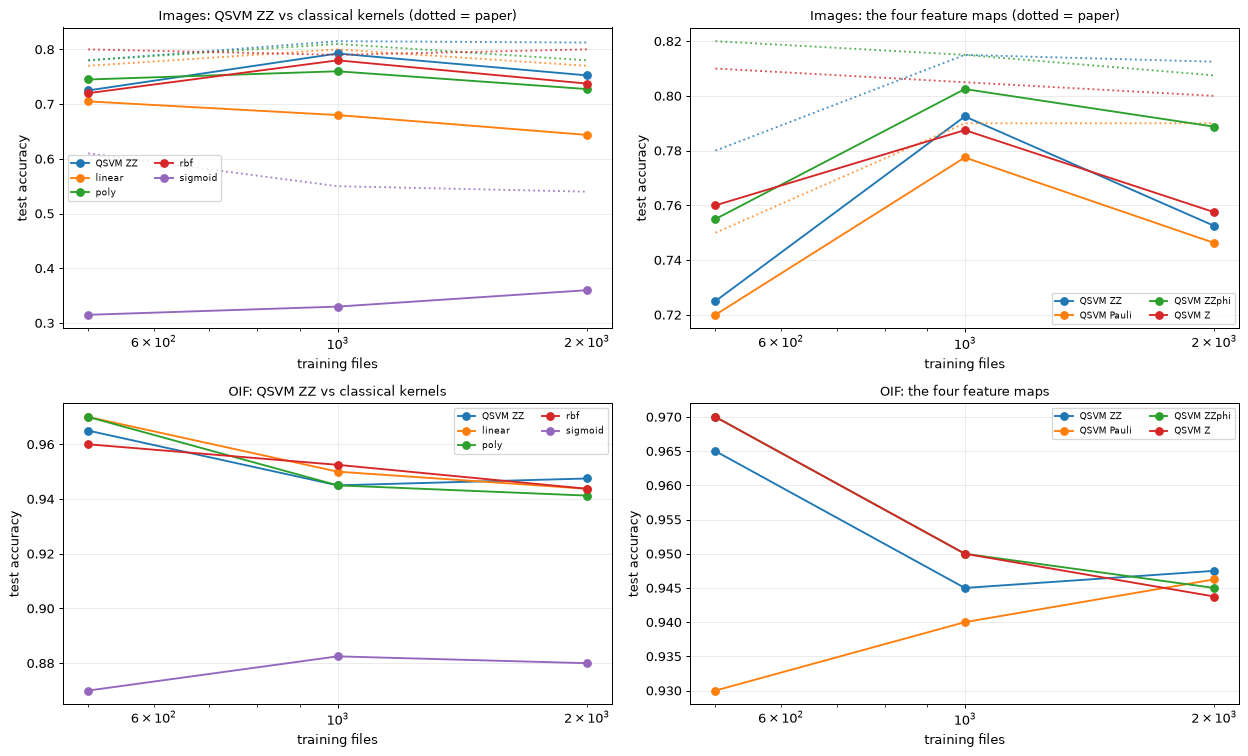

In [25]:
# ---- re-draw of the paper's Table 3/4 as curves: accuracy against the number of training files (4 qubits), this notebook (full lines) and the paper (dotted, Images only)
PAPER_SIZES = [(500, 100), (1000, 200), (2000, 400), (4000, 800), (8000, 1600), (16000, 4000)]
PAPER_T3 = {"QSVM ZZ": [.78, .815, .8125, .7925, .805, .81075], "linear": [.77, .80, .77, .78, .77, .77], "poly": [.78, .81, .78, .80, .79, .78],
            "rbf": [.80, .79, .80, .82, .82, .81], "sigmoid": [.61, .55, .54, .55, .55, .56]}
PAPER_T4 = {"QSVM ZZ": [.78, .815, .8125, .7925, .805, .81075], "QSVM Pauli": [.75, .79, .79, .786, .7975, .806], "QSVM ZZphi": [.82, .815, .8075, .811, .814, .805],
            "QSVM Z": [.81, .805, .80, .8075, .808, .799]}
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
for r, view in enumerate(("img", "oif")):
    d = QSVM_AGG[(QSVM_AGG.view == view) & (QSVM_AGG.qubits == QSVM_QUBITS)]
    for c, (models, paper) in enumerate([(["QSVM ZZ"] + CM, PAPER_T3), (QM, PAPER_T4)]):
        for m in models:
            g = d[d.model == m].set_index(["n_train", "n_test"]).reindex(QSVM_SIZES)
            line, = ax[r, c].plot([a for a, _ in QSVM_SIZES], g.acc.values, "o-", label=m)
            if view == "img":
                ax[r, c].plot([a for a, _ in PAPER_SIZES][:len(QSVM_SIZES)], paper[m][:len(QSVM_SIZES)], ":", color=line.get_color(), alpha=0.8)
        ax[r, c].set_xscale("log"); ax[r, c].set_xlabel("training files"); ax[r, c].set_ylabel("test accuracy")
        ax[r, c].set_title(("Images" if view == "img" else "OIF") + (": QSVM ZZ vs classical kernels" if c == 0 else ": the four feature maps") + (" (dotted = paper)" if view == "img" else ""), fontsize=10)
        ax[r, c].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 3. Quantum Neural Network (paper sections 3 and 4, Tables 12 to 57)

**The idea in plain words.** The QNN is a small parameterised quantum circuit (drawn in the circuit section above). The `N` input numbers (angles in `[0, pi/2]`) are written into `N` data qubits; layers of trainable rotations and CNOT gates mix them; two extra **ancilla qubits** are measured and their two `<Z>` values act as the scores of the classes *benign* and *malware*. Training minimises the **softmax cross-entropy** of those two scores by gradient descent with learning rate `eta`. The paper compares four ways of training/building the model:

| key | name | what changes |
|---|---|---|
| `ps` | **parameter-shift rule** | exact gradient from shifted circuit evaluations (two shifted circuits per trainable parameter and training file); batch size 1, so one update per file |
| `spsb` | **SPSB** (Hoffmann and Brown 2022) | one random sign direction `Delta` per file; the gradient is estimated from `f(theta + eps Delta) - f(theta - eps Delta)` along `Delta`, so the circuit is run a fixed number of times per file, independent of the number of parameters; batches of 32 files |
| `reup` | **data re-uploading** (Perez-Salinas et al. 2020) | the encoding block is repeated at the start of every layer |
| `both` | SPSB and re-uploading | both of the above |

**Classical comparison.** A small fully connected network (`NN_HIDDEN_WIDTH` units per hidden layer, ReLU, plain SGD with the same learning rate, same number of layers and epochs as the QNN, same inputs) with batch size 1 for the 200-file test protocol and 16 for the 4 000-file protocol, as in the paper.

**Two test protocols of the paper.** Protocol **A**: 1 000 training files, tested on 200 files. Protocol **B**: 1 000 training files, tested on 4 000 files (`QNN_TEST_BIG`; fewer in FAST mode). Here each QNN is trained once and evaluated on both test sets (the 200 files are the first 200 of the balanced test set).

**Honest note on the parameter-shift runs.** The *values* of the gradients are exactly what the parameter-shift rule returns for noise-free expectation values; the circuit simulator computes them with the adjoint method in one forward and one backward pass instead of `2 x parameters` circuit runs, which makes 100 000 training steps feasible on a CPU. The equality was asserted above against explicit `+-pi/2` shifted circuit evaluations. The number of circuit evaluations the shift rule *would* need is reported alongside (`circuit runs` column), so the paper's cost comparison with SPSB can be discussed.

In [26]:
def softmax(e):
    p = np.exp(e - e.max(-1, keepdims=True)); return p / p.sum(-1, keepdims=True)

def qnn_predict(sim, theta, X, chunk=500):
    out = []
    for a in range(0, len(X), chunk):
        Xb = X[a:a + chunk]
        out.append(sim.expvals(np.repeat(theta[None], len(Xb), 0), Xb).argmax(1))
    return np.concatenate(out)

_QNN_DATA = {}
def qnn_data(ds, N, rep, n_train=QNN_TRAIN):
    """Training set (n_train files) and class-interleaved test set; transforms fitted on the training files only; angles in [0, pi/2]."""
    key = (ds, N, rep, n_train)
    if key not in _QNN_DATA:
        tr, te = draw_sample(n_train, QNN_TEST_BIG, 10 + rep)
        neg, pos = te[Y_ALL[te] == 0], te[Y_ALL[te] == 1]; te = np.column_stack([neg, pos]).ravel()        # prefixes are balanced
        _, _, Atr, Ate = prep("img" if ds == "Images" else "oif", tr, te, N, pi / 2)
        _QNN_DATA[key] = (Atr, Y_ALL[tr], Ate, Y_ALL[te])
    return _QNN_DATA[key]

def train_qnn(N, L, method, lr, epochs, data, seed):
    """method: ps | spsb | reup | both.  Returns the metrics record."""
    Atr, ytr, Ate, yte = data
    reupload, spsb = method in ("reup", "both"), method in ("spsb", "both")
    sim = QNNSim(N, L, reupload)
    rng = np.random.default_rng(seed)
    theta = rng.uniform(-pi, pi, sim.P)                       # CHOICE: uniform initial weights in [-pi, pi]
    n, hist, t0 = len(Atr), [], time.time()
    eye = np.eye(2)
    for ep in range(epochs):
        order = rng.permutation(n)
        if not spsb:                                          # exact gradient, batch size 1: one update per training file
            for i in order:
                tgt = eye[ytr[i]]
                _, g = sim.value_and_grad(theta, Atr[i], lambda e: softmax(e) - tgt)
                theta = theta - lr * g
        else:                                                 # SPSB: 3 circuit runs per file, batches of QNN_SPSB_BATCH
            for a in range(0, n, QNN_SPSB_BATCH):
                ib = order[a:a + QNN_SPSB_BATCH]; B = len(ib); Xb = Atr[ib]
                Delta = rng.choice([-1.0, 1.0], size=(B, sim.P))           # one random sign direction per file
                e0 = sim.expvals(np.repeat(theta[None], B, 0), Xb)
                d = (sim.expvals(theta[None] + QNN_SPSB_EPS * Delta, Xb) - sim.expvals(theta[None] - QNN_SPSB_EPS * Delta, Xb)) / (2 * QNN_SPSB_EPS)
                s = ((softmax(e0) - eye[ytr[ib]]) * d).sum(1)             # (dLoss/de) . (directional derivative of e)
                theta = theta - lr * (s[:, None] * Delta).mean(0)
        hist.append(float((qnn_predict(sim, theta, Atr) == ytr).mean()))
    t_train = time.time() - t0
    pred = qnn_predict(sim, theta, Ate)
    runs_per_file = 3 if spsb else 2 * sim.P + 1
    return dict(model="QNN", method=method, N=N, L=L, lr=lr, epochs=epochs, seed=seed, bs=QNN_SPSB_BATCH if spsb else 1, ntrain=n, params=sim.P,
                train_acc=hist[-1], curve=hist, test_A=float((pred[:QNN_TEST_SMALL] == yte[:QNN_TEST_SMALL]).mean()), test_B=float((pred == yte).mean()),
                time=t_train, circuit_runs=int(runs_per_file * n * epochs), theta=theta)

def train_nn(N, L, lr, epochs, data, bs, seed):
    Atr, ytr, Ate, yte = data
    clf = MLPClassifier(hidden_layer_sizes=(NN_HIDDEN_WIDTH,) * L, activation="relu", solver="sgd", learning_rate_init=lr, batch_size=bs,
                        momentum=0.0, nesterovs_momentum=False, alpha=0.0, shuffle=True, random_state=seed)
    hist, t0 = [], time.time()
    for ep in range(epochs):
        clf.partial_fit(Atr, ytr, classes=[0, 1]); hist.append(float(clf.score(Atr, ytr)))
    pred = clf.predict(Ate)
    return dict(model="NN", method="nn", N=N, L=L, lr=lr, epochs=epochs, seed=seed, bs=bs, ntrain=len(Atr), params=sum(c.size for c in clf.coefs_),
                train_acc=hist[-1], curve=hist, test_A=float((pred[:QNN_TEST_SMALL] == yte[:QNN_TEST_SMALL]).mean()), test_B=float((pred == yte).mean()),
                time=time.time() - t0, circuit_runs=0)

QNN_ROWS = []
QNN_METHODS = ["ps", "spsb", "reup", "both"]
def run_one(ds, N, L, method, lr, epochs, seed, rep=0, n_train=QNN_TRAIN, with_nn=False):
    data = qnn_data(ds, N, rep, n_train)
    r = train_qnn(N, L, method, lr, epochs, data, seed); r.update(ds=ds, rep=rep); QNN_ROWS.append(r)
    msg = f"  {ds:6s} QNN {method:4s} N={N} L={L:2d} lr={lr:<5} ep={epochs:2d} seed={seed}: train {r['train_acc']:.3f}  test A {r['test_A']:.3f}  test B {r['test_B']:.3f}  ({r['time']:.0f} s)"
    print(msg, flush=True)
    if with_nn:
        for bs in (1, 16):
            q = train_nn(N, L, lr, epochs, data, bs, seed); q.update(ds=ds, rep=rep); QNN_ROWS.append(q)
        print(f"  {ds:6s} NN        N={N} L={L:2d} lr={lr:<5} ep={epochs:2d} seed={seed}: bs1 test A {QNN_ROWS[-2]['test_A']:.3f} | bs16 test B {QNN_ROWS[-1]['test_B']:.3f}", flush=True)

In [27]:
# ---- Experiment C: the 1-epoch grid (Tables 12 to 28): qubits x layers x four methods, learning rate 0.1, both datasets
t_exp = time.time()
print(f"QNN grid: qubits {QNN_QUBITS}, layers {QNN_LAYERS}, methods {QNN_METHODS}, lr {QNN_GRID_LR}, 1 epoch, {QNN_TRAIN} training files")
for ds in ("Images", "OIF"):
    for N in QNN_QUBITS:
        for L in QNN_LAYERS:
            for mi, method in enumerate(QNN_METHODS):
                run_one(ds, N, L, method, QNN_GRID_LR, 1, SEED, with_nn=(mi == 0))
print(f"grid done in {time.time() - t_exp:.0f} s")

QNN grid: qubits [4], layers [1, 2, 3], methods ['ps', 'spsb', 'reup', 'both'], lr 0.1, 1 epoch, 1000 training files


  Images QNN ps   N=4 L= 1 lr=0.1   ep= 1 seed=42: train 0.509  test A 0.470  test B 0.507  (12 s)


  Images NN        N=4 L= 1 lr=0.1   ep= 1 seed=42: bs1 test A 0.620 | bs16 test B 0.550


  Images QNN spsb N=4 L= 1 lr=0.1   ep= 1 seed=42: train 0.484  test A 0.475  test B 0.493  (1 s)


  Images QNN reup N=4 L= 1 lr=0.1   ep= 1 seed=42: train 0.509  test A 0.470  test B 0.507  (16 s)


...

  OIF    NN        N=4 L= 3 lr=0.1   ep= 1 seed=42: bs1 test A 0.945 | bs16 test B 0.940


  OIF    QNN spsb N=4 L= 3 lr=0.1   ep= 1 seed=42: train 0.654  test A 0.645  test B 0.663  (4 s)


  OIF    QNN reup N=4 L= 3 lr=0.1   ep= 1 seed=42: train 0.943  test A 0.945  test B 0.935  (32 s)


  OIF    QNN both N=4 L= 3 lr=0.1   ep= 1 seed=42: train 0.701  test A 0.705  test B 0.698  (4 s)


grid done in 360 s


In [28]:
# ---- Experiment D: learning-rate scan with 2 layers (Tables 30 to 38); lr = 0.1 comes from the grid above
t_exp = time.time()
if QNN_LR_SCAN:
    print(f"learning-rate scan {QNN_LR_SCAN}")
    for ds in ("Images", "OIF"):
        for N in QNN_QUBITS:
            for lr in QNN_LR_SCAN:
                for mi, method in enumerate(QNN_METHODS):
                    run_one(ds, N, 2, method, lr, 1, SEED, with_nn=(mi == 0))
else:
    print("FAST_MODE: learning-rate scan skipped (Tables 30 to 38 are checked only at the grid's learning rate 0.1)")
print(f"scan done in {time.time() - t_exp:.0f} s")

FAST_MODE: learning-rate scan skipped (Tables 30 to 38 are checked only at the grid's learning rate 0.1)
scan done in 0 s


In [29]:
# ---- Experiment E: deeper models trained for several epochs (Tables 14 to 29, 39 to 57)
t_exp = time.time()
for (N, L, E, lr) in QNN_DEEP:
    print(f"deep model: {N} data qubits, {L} layers, {E} epochs, lr {lr}, seeds {QNN_DEEP_SEEDS}")
    for ds in ("Images", "OIF"):
        for si, seed in enumerate(QNN_DEEP_SEEDS):
            for mi, method in enumerate(QNN_METHODS):
                run_one(ds, N, L, method, lr, E, seed, rep=si, with_nn=(mi == 0))
print(f"deep models done in {time.time() - t_exp:.0f} s")

deep model: 4 data qubits, 5 layers, 3 epochs, lr 0.05, seeds [42]


  Images QNN ps   N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.660  test A 0.615  test B 0.645  (115 s)


  Images NN        N=4 L= 5 lr=0.05  ep= 3 seed=42: bs1 test A 0.500 | bs16 test B 0.639


  Images QNN spsb N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.585  test A 0.600  test B 0.603  (8 s)


  Images QNN reup N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.763  test A 0.730  test B 0.711  (145 s)


...

  OIF    NN        N=4 L= 5 lr=0.05  ep= 3 seed=42: bs1 test A 0.955 | bs16 test B 0.941


  OIF    QNN spsb N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.777  test A 0.785  test B 0.789  (15 s)


  OIF    QNN reup N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.945  test A 0.940  test B 0.932  (139 s)


  OIF    QNN both N=4 L= 5 lr=0.05  ep= 3 seed=42: train 0.911  test A 0.935  test B 0.912  (23 s)


deep models done in 636 s


In [30]:
# ---- Experiment F: Table 55 - SPSB on OIF with 10 000 training files (7 qubits, 5 layers, 5 epochs, lr 0.1)
if QNN_SPSB_BIG_TRAIN:
    t0 = time.time()
    run_one("OIF", 7, 5, "spsb", 0.1, 5, SEED, rep=0, n_train=QNN_SPSB_BIG_TRAIN)
    print(f"done in {time.time() - t0:.0f} s")
else:
    print("FAST_MODE: the 10 000-file SPSB run of Table 55 is skipped")
QNN = pd.DataFrame(QNN_ROWS)
print(len(QNN), "training runs recorded;", f"total QNN/NN time {QNN.time.sum() / 60:.1f} min")

FAST_MODE: the 10 000-file SPSB run of Table 55 is skipped
48 training runs recorded; total QNN/NN time 16.3 min


### QNN results in the layout of the paper

The cells below show the 1-epoch grid (qubits x layers, train/test accuracy) for the four training methods and for the classical network, then the epoch-by-epoch curves of the deeper models, and finally the confusion matrices of representative models (malware is the positive class).

In [31]:
QNN = pd.DataFrame(QNN_ROWS)
def cell_txt(d, col):
    return "-" if len(d) == 0 else f"{d.train_acc.mean():.3f} / {d[col].mean():.3f}"
def grid_table(ds, prot):
    col = "test_A" if prot == "A" else "test_B"
    d = QNN[(QNN.ds == ds) & (QNN.epochs == 1) & np.isclose(QNN.lr, QNN_GRID_LR) & (QNN.ntrain == QNN_TRAIN)]
    rows = {}
    for N in QNN_QUBITS:
        for L in QNN_LAYERS:
            r = {}
            for m in QNN_METHODS:
                r["QNN " + m] = cell_txt(d[(d.model == "QNN") & (d.method == m) & (d.N == N) & (d.L == L) & (d.seed == SEED)], col)
            r["classical NN (bs %d)" % (1 if prot == "A" else 16)] = cell_txt(d[(d.model == "NN") & (d.N == N) & (d.L == L) & (d.bs == (1 if prot == "A" else 16))], col)
            rows[f"{N} qubits / {L} layers"] = r
    return pd.DataFrame(rows).T
for ds in ("Images", "OIF"):
    for prot in ("A", "B"):
        print(f"=== {ds}, protocol {prot} ({QNN_TRAIN} train / {QNN_TEST_SMALL if prot == 'A' else QNN_TEST_BIG} test), 1 epoch, lr {QNN_GRID_LR}: train accuracy / test accuracy ===")
        display(grid_table(ds, prot))

=== Images, protocol A (1000 train / 200 test), 1 epoch, lr 0.1: train accuracy / test accuracy ===


,QNN ps,QNN spsb,QNN reup,QNN both,classical NN (bs 1)
4 qubits / 1 layers,0.509 / 0.470,0.484 / 0.475,0.509 / 0.470,0.484 / 0.475,0.635 / 0.620
4 qubits / 2 layers,0.622 / 0.575,0.566 / 0.560,0.633 / 0.555,0.465 / 0.425,0.500 / 0.500
4 qubits / 3 layers,0.654 / 0.630,0.519 / 0.525,0.696 / 0.675,0.535 / 0.535,0.506 / 0.510


=== Images, protocol B (1000 train / 1000 test), 1 epoch, lr 0.1: train accuracy / test accuracy ===


,QNN ps,QNN spsb,QNN reup,QNN both,classical NN (bs 16)
4 qubits / 1 layers,0.509 / 0.507,0.484 / 0.493,0.509 / 0.507,0.484 / 0.493,0.568 / 0.550
4 qubits / 2 layers,0.622 / 0.614,0.566 / 0.560,0.633 / 0.610,0.465 / 0.449,0.558 / 0.554
4 qubits / 3 layers,0.654 / 0.647,0.519 / 0.512,0.696 / 0.624,0.535 / 0.517,0.690 / 0.648


=== OIF, protocol A (1000 train / 200 test), 1 epoch, lr 0.1: train accuracy / test accuracy ===


,QNN ps,QNN spsb,QNN reup,QNN both,classical NN (bs 1)
4 qubits / 1 layers,0.576 / 0.535,0.462 / 0.510,0.576 / 0.535,0.462 / 0.510,0.940 / 0.965
4 qubits / 2 layers,0.943 / 0.955,0.461 / 0.475,0.940 / 0.945,0.530 / 0.510,0.924 / 0.915
4 qubits / 3 layers,0.940 / 0.955,0.654 / 0.645,0.943 / 0.945,0.701 / 0.705,0.942 / 0.945


=== OIF, protocol B (1000 train / 1000 test), 1 epoch, lr 0.1: train accuracy / test accuracy ===


,QNN ps,QNN spsb,QNN reup,QNN both,classical NN (bs 16)
4 qubits / 1 layers,0.576 / 0.581,0.462 / 0.471,0.576 / 0.581,0.462 / 0.471,0.934 / 0.931
4 qubits / 2 layers,0.943 / 0.939,0.461 / 0.460,0.940 / 0.933,0.530 / 0.534,0.881 / 0.878
4 qubits / 3 layers,0.940 / 0.936,0.654 / 0.663,0.943 / 0.935,0.701 / 0.698,0.941 / 0.940


In [32]:
# ---- learning-rate scan (Tables 30 to 38 layout), only when it was run
if QNN_LR_SCAN:
    d = QNN[(QNN.L == 2) & (QNN.epochs == 1) & (QNN.ntrain == QNN_TRAIN) & (QNN.seed == SEED)]
    rows = {}
    for ds in ("Images", "OIF"):
        for N in QNN_QUBITS:
            for m in QNN_METHODS + ["nn"]:
                r = {}
                for lr in sorted(set(QNN_LR_SCAN + [QNN_GRID_LR])):
                    x = d[(d.ds == ds) & (d.N == N) & (d.method == m) & np.isclose(d.lr, lr) & ((d.bs == 16) if m == "nn" else True)]
                    r[f"lr={lr}"] = cell_txt(x, "test_B")
                rows[f"{ds} {N}q/2L {m}"] = r
    print("Train / test accuracy (protocol B), 2 layers, 1 epoch")
    display(pd.DataFrame(rows).T)
else:
    print("FAST_MODE: no learning-rate scan was run.")

FAST_MODE: no learning-rate scan was run.


In [33]:
# ---- deeper models: accuracy epoch by epoch (Tables 14 to 29, 39 to 57 layout)
def epoch_table(N, L, E, lr, ds, prot):
    d = QNN[(QNN.N == N) & (QNN.L == L) & (QNN.epochs == E) & np.isclose(QNN.lr, lr) & (QNN.ds == ds) & (QNN.ntrain == QNN_TRAIN)]
    rows = {}
    for m in QNN_METHODS + ["nn"]:
        x = d[(d.method == m) & ((d.bs == (1 if prot == "A" else 16)) if m == "nn" else True)]
        if len(x) == 0: continue
        H = np.mean([h for h in x["curve"]], axis=0)
        r = {f"epoch {i + 1}": f"{H[i]:.3f}" for i in range(E)}; r["test"] = f"{x['test_A' if prot == 'A' else 'test_B'].mean():.3f}"
        rows[m] = r
    return pd.DataFrame(rows).T
for (N, L, E, lr) in QNN_DEEP:
    for ds in ("Images", "OIF"):
        print(f"=== {ds}: {N} qubits, {L} layers, {E} epochs, lr {lr}: training accuracy after each epoch, test accuracy (protocol B), mean over seeds {QNN_DEEP_SEEDS} ===")
        display(epoch_table(N, L, E, lr, ds, "B"))

=== Images: 4 qubits, 5 layers, 3 epochs, lr 0.05: training accuracy after each epoch, test accuracy (protocol B), mean over seeds [42] ===


,epoch 1,epoch 2,epoch 3,test
ps,0.687,0.638,0.660,0.645
spsb,0.544,0.611,0.585,0.603
reup,0.701,0.706,0.763,0.711
both,0.597,0.624,0.631,0.633
nn,0.567,0.637,0.672,0.639


=== OIF: 4 qubits, 5 layers, 3 epochs, lr 0.05: training accuracy after each epoch, test accuracy (protocol B), mean over seeds [42] ===


,epoch 1,epoch 2,epoch 3,test
ps,0.942,0.942,0.939,0.940
spsb,0.530,0.774,0.777,0.789
reup,0.941,0.946,0.945,0.932
both,0.612,0.874,0.911,0.912
nn,0.901,0.937,0.937,0.941


In [34]:
# ---- Table 55 (SPSB, OIF, 10 000 training files)
d = QNN[QNN.ntrain == 10000]
if len(d):
    H = d["curve"].iloc[0]
    print("SPSB, OIF, 7 qubits, 5 layers, 5 epochs, 10 000 training files: training accuracy per epoch", np.round(H, 3).tolist(), "| test (4000 files)", round(d.test_B.iloc[0], 3))
else:
    print("FAST_MODE: Table 55 run skipped.")

FAST_MODE: Table 55 run skipped.


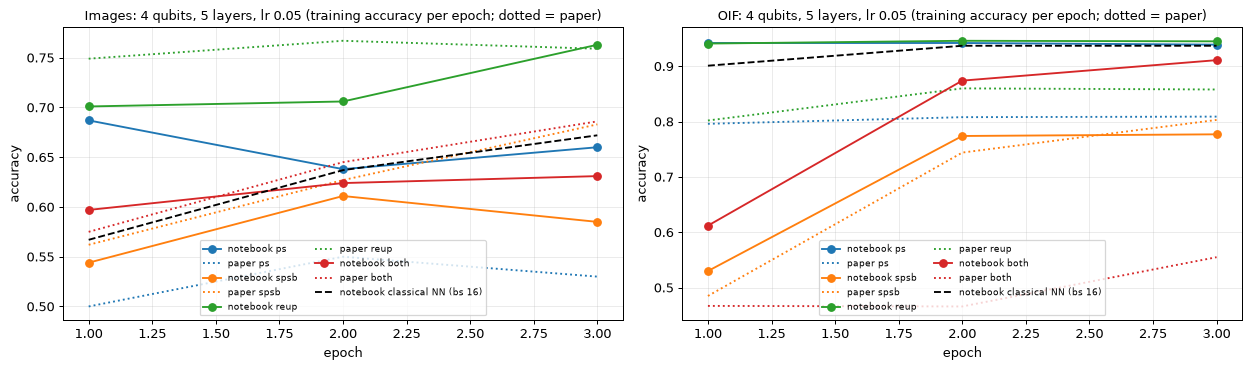

In [35]:
# ---- training curves, notebook against the paper: 4 qubits, 5 layers (first deep model), training accuracy per epoch
PAPER_CURVE_4Q5L = {   # Tables 18, 22 (parameter shift), 25 (SPSB), 27 (re-uploading), 29 (both): training accuracy after each of 10 epochs
    ("Images", "ps"): [.5, .55, .53, .52, .53, .56, .57, .56, .55, .54], ("OIF", "ps"): [.796, .808, .809, .809, .809, .809, .809, .809, .809, .809],
    ("Images", "spsb"): [.562, .627, .683, .709, .719, .713, .731, .738, .74, .744], ("OIF", "spsb"): [.485, .744, .803, .814, .816, .816, .816, .816, .817, .817],
    ("Images", "reup"): [.749, .767, .759, .755, .75, .755, .754, .754, .754, .753], ("OIF", "reup"): [.802, .86, .858, .86, .86, .863, .863, .864, .863, .862],
    ("Images", "both"): [.575, .645, .686, .725, .735, .736, .742, .746, .753, .746], ("OIF", "both"): [.467, .466, .555, .675, .834, .843, .848, .857, .856, .865]}
cfg = QNN_DEEP[0]; N0, L0, E0, lr0 = cfg
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, ds in zip(ax, ("Images", "OIF")):
    for i, m in enumerate(QNN_METHODS):
        x = QNN[(QNN.N == N0) & (QNN.L == L0) & (QNN.epochs == E0) & np.isclose(QNN.lr, lr0) & (QNN.ds == ds) & (QNN.method == m)]
        if len(x) == 0: continue
        H = np.mean([h for h in x["curve"]], axis=0); line, = a.plot(range(1, E0 + 1), H, "o-", color=f"C{i}", label=f"notebook {m}")
        a.plot(range(1, E0 + 1), PAPER_CURVE_4Q5L[(ds, m)][:E0], ":", color=f"C{i}", label=f"paper {m}")
    x = QNN[(QNN.N == N0) & (QNN.L == L0) & (QNN.epochs == E0) & np.isclose(QNN.lr, lr0) & (QNN.ds == ds) & (QNN.method == "nn") & (QNN.bs == 16)]
    if len(x): a.plot(range(1, E0 + 1), np.mean([h for h in x["curve"]], axis=0), "k--", label="notebook classical NN (bs 16)")
    a.set_title(f"{ds}: {N0} qubits, {L0} layers, lr {lr0} (training accuracy per epoch; dotted = paper)", fontsize=10); a.set_xlabel("epoch"); a.set_ylabel("accuracy"); a.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

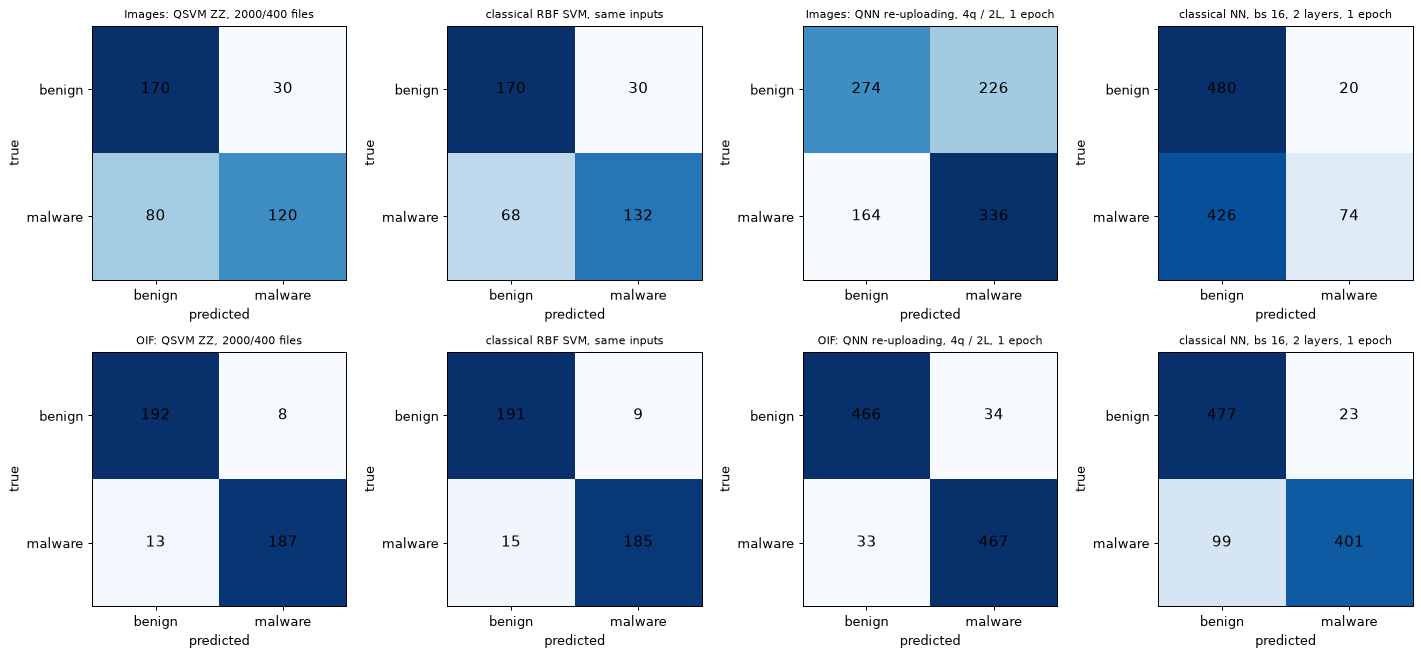

In [36]:
# ---- confusion matrices (malware = positive class) of representative models; each is retrained here with the settings printed in the title
def conf_plot(ax, y, p, title):
    cm = confusion_matrix(y, p, labels=[0, 1]); ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "malware"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "malware"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)
n_c, m_c = QSVM_SIZES[min(2, len(QSVM_SIZES) - 1)]
fig, ax = plt.subplots(2, 4, figsize=(16, 7.4))
for r, view in enumerate(("img", "oif")):
    tr, te = draw_sample(n_c, m_c, 0); _, _, Atr, Ate = prep(view, tr, te, 4, pi); ytr, yte = Y_ALL[tr], Y_ALL[te]
    s = tune_bw("zz", 4, Atr, ytr); fm = FMSim(4, "zz"); Str, Ste = fm.states(Atr * s), fm.states(Ate * s)
    p = SVC(kernel="precomputed", C=SVM_C).fit(gram(Str, Str), ytr).predict(gram(Ste, Str))
    conf_plot(ax[r, 0], yte, p, f"{'Images' if view == 'img' else 'OIF'}: QSVM ZZ, {n_c}/{m_c} files")
    conf_plot(ax[r, 1], yte, SVC(kernel="rbf").fit(Atr, ytr).predict(Ate), "classical RBF SVM, same inputs")
    ds = "Images" if view == "img" else "OIF"
    Ntr, Ltr = 4, 2
    data = qnn_data(ds, Ntr, 0); Atr_q, ytr_q, Ate_q, yte_q = data
    res = train_qnn(Ntr, Ltr, "reup", 0.1, 1, data, SEED)
    p_q = qnn_predict(QNNSim(Ntr, Ltr, True), res["theta"], Ate_q)
    conf_plot(ax[r, 2], yte_q, p_q, f"{ds}: QNN re-uploading, 4q / 2L, 1 epoch")
    nn = MLPClassifier(hidden_layer_sizes=(NN_HIDDEN_WIDTH,) * 2, solver="sgd", learning_rate_init=0.1, batch_size=16, momentum=0.0, alpha=0.0, random_state=SEED)
    nn.partial_fit(Atr_q, ytr_q, classes=[0, 1]); conf_plot(ax[r, 3], yte_q, nn.predict(Ate_q), "classical NN, bs 16, 2 layers, 1 epoch")
plt.tight_layout(); plt.show()

## 4. Side by side with the paper: one verdict per claim

The next cells type in every number of the paper that can be tested (Tables 3 to 6, 11, 12 to 57) and compare it with this notebook's value. **Verdict rule:** `reproduced` if the notebook value is within 2 accuracy points (0.02 F1) of the paper's, `exceeded` if it is higher by more, `not reached` if it is lower by more, `cannot be checked` if the quantity needs something this notebook does not have (IBM hardware, the paper's private data) or was not run in `FAST_MODE`. Remember what these verdicts mean: the data differ (BODMAS features instead of the paper's byte images and private OIF features), most paper cells are **single runs** on 100 to 4 000 test files (one file is 0.5 to 1 accuracy point), and the paper's QNN numbers jump by tens of points between neighbouring settings. A cell-by-cell match is therefore not expected; the claim-level verdicts at the end matter more.

In [37]:
# ============================== numbers typed in from the paper (arXiv:2305.09674v3) ==============================
# --- QSVM, Images view.  Sizes as PAPER_SIZES.
P_T3 = {"QSVM ZZ": [.78, .815, .8125, .7925, .805, .81075], "linear": [.77, .80, .77, .78, .77, .77], "poly": [.78, .81, .78, .80, .79, .78],
        "rbf": [.80, .79, .80, .82, .82, .81], "sigmoid": [.61, .55, .54, .55, .55, .56]}
P_T3_F1 = {"QSVM ZZ": [.778, .838, .827, .805, .811, .814]}
P_T4 = {"QSVM Pauli": [.75, .79, .79, .786, .7975, .806], "QSVM ZZphi": [.82, .815, .8075, .811, .814, .805], "QSVM Z": [.81, .805, .80, .8075, .808, .799]}
QUB = [3, 4, 6, 7]       # Tables 5, 6, 11: columns 3 (2000/400), 4 (2000/400), 6 (1000/200), 7 (1000/200)
P_T5 = {"QSVM ZZ": [.7675, .8125, .81, .825], "QSVM Pauli": [.7575, .79, .715, .765], "QSVM ZZphi": [.8, .8075, .79, .785], "QSVM Z": [.7825, .8, .785, .78],
        "linear": [.79, .77, .79, .79], "poly": [.77, .78, .80, .80], "rbf": [.81, .8, .8, .8], "sigmoid": [.42, .54, .53, .57]}
P_T6 = {"QSVM ZZ": [.79, .827, .828, .844], "QSVM Pauli": [.774, .814, .739, .791], "QSVM ZZphi": [.819, .826, .817, .810], "QSVM Z": [.804, .819, .815, .810]}
P_T11 = {"QSVM ZZ": [.859, .901, .843, .814], "QSVM Pauli": [.925, .926, .913, .909], "QSVM ZZphi": [.933, .90, .932, .919], "QSVM Z": [.931, .917, .932, .914]}

# --- QNN, 1 epoch, lr 0.1, 2 layers..: (dataset, method, model, protocol) -> {(qubits, layers): (train, test)}   Tables 12, 13, 16, 17, 20, 21, 24, 26, 28
def _g(t4, t7): return {(4, 1): t4[0], (4, 2): t4[1], (4, 3): t4[2], (7, 1): t7[0], (7, 2): t7[1], (7, 3): t7[2]}
PAPER_GRID = {
    ("Images", "ps", "QNN", "A"): _g([(.584, .74), (.609, .605), (.606, .74)], [(.537, .51), (.513, .445), (.539, .545)]),                      # T12
    ("Images", "nn", "NN", "A"):  _g([(.489, .33), (.489, .41), (.492, .40)], [(.489, .42), (.489, .435), (.492, .475)]),                       # T13
    ("Images", "ps", "QNN", "B"): _g([(.5, .518), (.515, .508), (.542, .512)], [(.513, .497), (.537, .5077), (.526, .5125)]),                   # T16
    ("Images", "nn", "NN", "B"):  _g([(.657, .761), (.668, .630), (.677, .6575)], [(.684, .779), (.663, .5573), (.703, .7638)]),               # T17
    ("OIF", "ps", "QNN", "B"):    _g([(.698, .667), (.677, .667), (.803, .819)], [(.697, .784), (.487, .504), (.802, .804)]),                   # T20
    ("OIF", "nn", "NN", "B"):     _g([(.489, .1965), (.837, .591), (.848, .7588)], [(.844, .5545), (.829, .5312), (.841, .7377)]),             # T21
    ("OIF", "spsb", "QNN", "B"):  _g([(.73, .725), (.567, .62), (.641, .657)], [(.441, .635), (.503, .48), (.81, .809)]),                       # T24
    ("Images", "spsb", "QNN", "B"): _g([(.552, .53), (.457, .4315), (.572, .5985)], [(.521, .501), (.548, .569), (.535, .534)]),               # T24
    ("OIF", "reup", "QNN", "B"):  _g([(.698, .667), (.722, .879), (.637, .64)], [(.697, .784), (.805, .80725), (.804, .86925)]),               # T26
    ("Images", "reup", "QNN", "B"): _g([(.5, .518), (.63, .52175), (.677, .75325)], [(.513, .497), (.549, .74775), (.602, .52925)]),           # T26
    ("OIF", "both", "QNN", "B"):  _g([(.73, .725), (.561, .61075), (.468, .479)], [(.441, .635), (.709, .77075), (.432, .514)]),               # T28
    ("Images", "both", "QNN", "B"): _g([(.552, .53), (.46, .46), (.49, .5005)], [(.521, .501), (.545, .54625), (.512, .54125)]),               # T28
}
# --- learning-rate scan, 2 layers (Tables 30 to 38): (dataset, method, model, protocol) -> {(qubits, lr): (train, test)}
def _l(a4, a7): return {(4, .01): a4[0], (4, .1): a4[1], (4, .5): a4[2], (7, .01): a7[0], (7, .1): a7[1], (7, .5): a7[2]}
PAPER_LR = {
    ("Images", "ps", "QNN", "A"): _l([(.5, .525), (.609, .605), (.552, .502)], [(.548, .475), (.513, .445), (.491, .445)]),                    # T30
    ("Images", "nn", "NN", "A"):  _l([(.504, .585), (.489, .41), (.505, .42)], [(.504, .595), (.489, .435), (.505, .58)]),                      # T31
    ("Images", "ps", "QNN", "B"): _l([(.49, .495), (.515, .508), (.517, .509)], [(.543, .565), (.537, .5077), (.527, .509)]),                   # T32
    ("Images", "nn", "NN", "B"):  _l([(.748, .639), (.668, .630), (.630, .6695)], [(.740, .7775), (.663, .5573), (.634, .5228)]),              # T33
    ("OIF", "ps", "QNN", "B"):    _l([(.641, .6695), (.677, .667), (.687, .839)], [(.503, .482), (.487, .504), (.637, .80025)]),                # T34
    ("OIF", "nn", "NN", "B"):     _l([(.85, .711), (.837, .591), (.812, .4695)], [(.854, .8953), (.829, .5312), (.806, .4715)]),               # T35
    ("OIF", "spsb", "QNN", "B"):  _l([(.482, .485), (.567, .62), (.672, .80)], [(.503, .4805), (.503, .48), (.506, .4785)]),                   # T36
    ("Images", "spsb", "QNN", "B"): _l([(.462, .439), (.457, .4315), (.484, .531)], [(.548, .5705), (.548, .569), (.544, .571)]),              # T36
    ("OIF", "reup", "QNN", "B"):  _l([(.641, .6685), (.722, .879), (.748, .8715)], [(.767, .804), (.805, .80725), (.803, .80775)]),             # T37
    ("Images", "reup", "QNN", "B"): _l([(.509, .51975), (.63, .52175), (.577, .48925)], [(.534, .53675), (.549, .74775), (.516, .5085)]),       # T37
    ("OIF", "both", "QNN", "B"):  _l([(.478, .48275), (.561, .61075), (.655, .7935)], [(.643, .645), (.709, .77075), (.77, .80775)]),           # T38
    ("Images", "both", "QNN", "B"): _l([(.483, .4605), (.46, .46), (.537, .752)], [(.543, .54), (.545, .54625), (.561, .578)]),                 # T38
}
# --- deeper models: (qubits, layers, epochs, lr) -> {(dataset, method, model, protocol): (training accuracy of the last epoch, test accuracy)}
PAPER_DEEP = {
    (4, 5, 10, .05): {("Images", "ps", "QNN", "A"): (.62, .64), ("Images", "nn", "NN", "A"): (.487, .54), ("Images", "ps", "QNN", "B"): (.54, .55),     # T14, T15, T18
                      ("Images", "nn", "NN", "B"): (.758, .7333), ("OIF", "ps", "QNN", "B"): (.809, .81), ("OIF", "nn", "NN", "B"): (.894, .847),           # T19, T22, T23
                      ("OIF", "spsb", "QNN", "B"): (.817, .8195), ("Images", "spsb", "QNN", "B"): (.744, .7275),                                          # T25
                      ("OIF", "reup", "QNN", "B"): (.862, .8705), ("Images", "reup", "QNN", "B"): (.753, .7095),                                          # T27
                      ("OIF", "both", "QNN", "B"): (.865, .864), ("Images", "both", "QNN", "B"): (.746, .75425)},                                        # T29
    (4, 10, 10, .05): {("Images", "ps", "QNN", "A"): (.674, .755), ("Images", "nn", "NN", "A"): (.488, .54), ("Images", "ps", "QNN", "B"): (.57, .53),   # T39, T40, T41
                       ("Images", "nn", "NN", "B"): (.74, .49), ("OIF", "ps", "QNN", "B"): (.812, .8135), ("OIF", "nn", "NN", "B"): (.881, .89),        # T42, T43, T44
                       ("OIF", "spsb", "QNN", "B"): (.815, .8167), ("Images", "spsb", "QNN", "B"): (.728, .67925),                                       # T45
                       ("OIF", "reup", "QNN", "B"): (.873, .88175), ("Images", "reup", "QNN", "B"): (.759, .77),                                         # T46
                       ("OIF", "both", "QNN", "B"): (.874, .876), ("Images", "both", "QNN", "B"): (.764, .76425)},                                       # T47
    (7, 5, 5, .1): {("Images", "ps", "QNN", "A"): (.58, .55), ("Images", "nn", "NN", "A"): (.519, .60), ("Images", "ps", "QNN", "B"): (.544, .5425),     # T48, T49, T50
                    ("Images", "nn", "NN", "B"): (.769, .7845), ("OIF", "ps", "QNN", "B"): (.818, .815), ("OIF", "nn", "NN", "B"): (.87, .889),          # T51, T52, T53
                    ("OIF", "spsb", "QNN", "B"): (.81, .8135), ("Images", "spsb", "QNN", "B"): (.521, .559),                                             # T54
                    ("OIF", "reup", "QNN", "B"): (.873, .881), ("Images", "reup", "QNN", "B"): (.736, .71625),                                           # T56
                    ("OIF", "both", "QNN", "B"): (.777, .7825), ("Images", "both", "QNN", "B"): (.486, .515)},                                           # T57
}
PAPER_T55 = (.8251, .82025)       # SPSB, OIF, 10 000 training files, 7 qubits, 5 layers, 5 epochs: training accuracy of the last epoch, test accuracy
print("paper values typed in:", sum(len(v) for v in PAPER_GRID.values()), "grid cells,", sum(len(v) for v in PAPER_LR.values()), "learning-rate cells,",
      sum(len(v) for v in PAPER_DEEP.values()), "deep-model cells; QSVM Tables 3, 4, 5, 6, 11")

paper values typed in: 72 grid cells, 72 learning-rate cells, 36 deep-model cells; QSVM Tables 3, 4, 5, 6, 11


In [38]:
def verdict(paper, mine, tol):
    if mine is None or (isinstance(mine, float) and np.isnan(mine)): return "cannot be checked"
    if mine > paper + tol + 1e-12: return "exceeded"
    if mine < paper - tol - 1e-12: return "not reached"
    return "reproduced"

CMP = []
def add(table, quantity, paper, mine, tol=TOL_ACC):
    CMP.append(dict(table=table, quantity=quantity, paper=paper, notebook=None if mine is None else round(float(mine), 4),
                    gap=None if mine is None else round(float(mine) - paper, 4), verdict=verdict(paper, mine, tol) if mine is not None else "cannot be checked (not run in FAST_MODE)"))

# ---- QSVM tables
def qsvm_val(view, k, ntr, nte, model, metric="acc"):
    d = QSVM_AGG[(QSVM_AGG.view == view) & (QSVM_AGG.qubits == k) & (QSVM_AGG.n_train == ntr) & (QSVM_AGG.n_test == nte) & (QSVM_AGG.model == model)]
    return float(d[metric].iloc[0]) if len(d) else None
for i, (ntr, nte) in enumerate(PAPER_SIZES):
    for m, v in {**P_T3, **P_T4}.items():
        add("T3/T4 acc (Images)", f"{m} {ntr}/{nte}", v[i], qsvm_val("img", QSVM_QUBITS, ntr, nte, m))
    add("T3 F1 (Images)", f"QSVM ZZ {ntr}/{nte}", P_T3_F1["QSVM ZZ"][i], qsvm_val("img", QSVM_QUBITS, ntr, nte, "QSVM ZZ", "f1"), TOL_F1)
sweep_paper = {3: (2000, 400), 4: (2000, 400), 6: (1000, 200), 7: (1000, 200)}
for j, k in enumerate(QUB):
    ntr, nte = QUBIT_SWEEP.get(k, sweep_paper[k]); same_size = (ntr, nte) == sweep_paper[k]
    for m, v in P_T5.items():
        add("T5 acc (Images)", f"{m}, {k} qubits", v[j], qsvm_val("img", k, ntr, nte, m) if same_size else None)
    for m, v in P_T6.items():
        add("T6 F1 (Images)", f"{m}, {k} qubits", v[j], qsvm_val("img", k, ntr, nte, m, "f1") if same_size else None, TOL_F1)
    for m, v in P_T11.items():
        add("T11 F1 (OIF)", f"{m}, {k} qubits", v[j], qsvm_val("oif", k, ntr, nte, m, "f1") if same_size else None, TOL_F1)
for m in ("QSVM ZZ", "QSVM Pauli", "QSVM ZZphi", "QSVM Z"):
    pass
T7_PAPER = {"QSVM ZZ": (.75, .80), "QSVM Pauli": (.80, .83), "QSVM ZZphi": (.55, .709), "QSVM Z": (.75, .78)}
for m, (a, f) in T7_PAPER.items():
    CMP.append(dict(table="T7 (IBM hardware)", quantity=f"{m} acc / F1 (paper {a} / {f})", paper=a, notebook=round(float(T7.loc[m, "acc"]), 3), gap=None, verdict="cannot be checked (hardware; ideal simulation shown)"))

# ---- QNN tables
def nb_qnn(ds, method, model, prot, N, L, lr, epochs, ntrain=QNN_TRAIN):
    d = QNN[(QNN.ds == ds) & (QNN.model == model) & (QNN.method == method) & (QNN.N == N) & (QNN.L == L) & np.isclose(QNN.lr, lr) & (QNN.epochs == epochs) & (QNN.ntrain == ntrain)]
    if model == "NN": d = d[d.bs == (1 if prot == "A" else 16)]
    if len(d) == 0: return None, None
    return float(d.train_acc.mean()), float(d["test_A" if prot == "A" else "test_B"].mean())
for (ds, method, model, prot), cells in PAPER_GRID.items():
    for (N, L), (ptr, pte) in cells.items():
        tr, te = nb_qnn(ds, method, model, prot, N, L, QNN_GRID_LR, 1)
        add("T12-T28 grid", f"{ds} {method} {model} prot {prot} {N}q/{L}L train", ptr, tr); add("T12-T28 grid", f"{ds} {method} {model} prot {prot} {N}q/{L}L test", pte, te)
for (ds, method, model, prot), cells in PAPER_LR.items():
    for (N, lr), (ptr, pte) in cells.items():
        if np.isclose(lr, QNN_GRID_LR): continue                                    # lr 0.1 is already in the grid comparison
        tr, te = nb_qnn(ds, method, model, prot, N, 2, lr, 1)
        add("T30-T38 lr scan", f"{ds} {method} {model} prot {prot} {N}q/2L lr {lr} train", ptr, tr); add("T30-T38 lr scan", f"{ds} {method} {model} prot {prot} {N}q/2L lr {lr} test", pte, te)
for (N, L, E, lr), cells in PAPER_DEEP.items():
    for (ds, method, model, prot), (ptr, pte) in cells.items():
        tr, te = nb_qnn(ds, method, model, prot, N, L, lr, E)
        add("T14-T57 deep", f"{ds} {method} {model} prot {prot} {N}q/{L}L/{E}ep last-epoch train", ptr, tr); add("T14-T57 deep", f"{ds} {method} {model} prot {prot} {N}q/{L}L/{E}ep test", pte, te)
tr55, te55 = nb_qnn("OIF", "spsb", "QNN", "B", 7, 5, 0.1, 5, ntrain=10000) if QNN_SPSB_BIG_TRAIN else (None, None)
add("T55", "OIF spsb 7q/5L/5ep, 10000 train: last-epoch train", PAPER_T55[0], tr55); add("T55", "OIF spsb 7q/5L/5ep, 10000 train: test", PAPER_T55[1], te55)

CMPDF = pd.DataFrame(CMP)
CMPDF["verdict_short"] = CMPDF.verdict.str.split(" \\(").str[0].str.replace("cannot be checked.*", "cannot be checked", regex=True)
print("Verdict counts per table group (each paper number is one cell):")
display(pd.crosstab(CMPDF.table, CMPDF.verdict_short, margins=True))

Verdict counts per table group (each paper number is one cell):


verdict_short,cannot be checked,exceeded,not reached,reproduced,All
table,,,,,
T11 F1 (OIF),8,8,0,0,16
T12-T28 grid,72,29,27,16,144
T14-T57 deep,72,0,0,0,72
T3 F1 (Images),3,0,3,0,6
T3/T4 acc (Images),24,0,19,5,48
T30-T38 lr scan,96,0,0,0,96
T5 acc (Images),16,8,4,4,32
T55,2,0,0,0,2
T6 F1 (Images),8,4,0,4,16


In [39]:
pd.set_option("display.max_rows", 700, "display.width", 220, "display.max_colwidth", 90)
print("Full side-by-side list, QSVM tables (Images and OIF)")
display(CMPDF[CMPDF.table.str.startswith(("T3", "T5", "T6", "T7", "T11"))][["table", "quantity", "paper", "notebook", "gap", "verdict"]].reset_index(drop=True))

Full side-by-side list, QSVM tables (Images and OIF)


,table,quantity,paper,notebook,gap,verdict
0,T3/T4 acc (Images),QSVM ZZ 500/100,0.78000,0.7250,-0.0550,not reached
1,T3/T4 acc (Images),linear 500/100,0.77000,0.7050,-0.0650,not reached
2,T3/T4 acc (Images),poly 500/100,0.78000,0.7450,-0.0350,not reached
3,T3/T4 acc (Images),rbf 500/100,0.80000,0.7200,-0.0800,not reached
4,T3/T4 acc (Images),sigmoid 500/100,0.61000,0.3150,-0.2950,not reached
5,T3/T4 acc (Images),QSVM Pauli 500/100,0.75000,0.7200,-0.0300,not reached
6,T3/T4 acc (Images),QSVM ZZphi 500/100,0.82000,0.7550,-0.0650,not reached
7,T3/T4 acc (Images),QSVM Z 500/100,0.81000,0.7600,-0.0500,not reached
8,T3 F1 (Images),QSVM ZZ 500/100,0.77800,0.6814,-0.0966,not reached
9,T3/T4 acc (Images),QSVM ZZ 1000/200,0.81500,0.7925,-0.0225,not reached


In [40]:
print("Full side-by-side list, QNN tables")
display(CMPDF[~CMPDF.table.str.startswith(("T3", "T5", "T6", "T7", "T11"))][["table", "quantity", "paper", "notebook", "gap", "verdict"]].reset_index(drop=True))

Full side-by-side list, QNN tables


,table,quantity,paper,notebook,gap,verdict
0,T12-T28 grid,Images ps QNN prot A 4q/1L train,0.58400,0.509,-0.0750,not reached
1,T12-T28 grid,Images ps QNN prot A 4q/1L test,0.74000,0.470,-0.2700,not reached
2,T12-T28 grid,Images ps QNN prot A 4q/2L train,0.60900,0.622,0.0130,reproduced
3,T12-T28 grid,Images ps QNN prot A 4q/2L test,0.60500,0.575,-0.0300,not reached
4,T12-T28 grid,Images ps QNN prot A 4q/3L train,0.60600,0.654,0.0480,exceeded
5,T12-T28 grid,Images ps QNN prot A 4q/3L test,0.74000,0.630,-0.1100,not reached
6,T12-T28 grid,Images ps QNN prot A 7q/1L train,0.53700,NaN,NaN,cannot be checked (not run in FAST_MODE)
7,T12-T28 grid,Images ps QNN prot A 7q/1L test,0.51000,NaN,NaN,cannot be checked (not run in FAST_MODE)
8,T12-T28 grid,Images ps QNN prot A 7q/2L train,0.51300,NaN,NaN,cannot be checked (not run in FAST_MODE)
9,T12-T28 grid,Images ps QNN prot A 7q/2L test,0.44500,NaN,NaN,cannot be checked (not run in FAST_MODE)


In [41]:
# ============================== claim-level verdicts (the paper's statements, tested on this notebook's numbers) ==============================
CLAIMS = []
def claim(text, ok, evidence, checkable=True):
    CLAIMS.append(dict(claim=text, verdict=("reproduced" if ok else "not reached") if checkable else "cannot be checked", evidence=evidence))
def A(view, k, size, model, metric="acc"): return qsvm_val(view, k, size[0], size[1], model, metric)
S = QSVM_SIZES

# C1  QSVM ZZ is comparable to (or better than) the best linear/poly/rbf SVM on Images at every size
gaps = [A("img", QSVM_QUBITS, s, "QSVM ZZ") - max(A("img", QSVM_QUBITS, s, c) for c in ("linear", "poly", "rbf")) for s in S]
claim("C1  Images, 4 qubits: the ZZ QSVM is comparable to the best of linear / poly / RBF SVM (paper: within about +-1 point, sometimes better)",
      all(g >= -TOL_ACC for g in gaps), "gap QSVM ZZ - best classical per size: " + ", ".join(f"{s[0]}:{g:+.3f}" for s, g in zip(S, gaps)))
# C2  sigmoid kernel is clearly the worst classical kernel
sg = [A("img", QSVM_QUBITS, s, "sigmoid") for s in S]; rb = [A("img", QSVM_QUBITS, s, "rbf") for s in S]
claim("C2  the sigmoid kernel is far worse than the other classical kernels (paper: 0.54 to 0.61 against 0.77 to 0.82)", np.mean(rb) - np.mean(sg) > 0.10,
      f"mean accuracy sigmoid {np.mean(sg):.3f} against rbf {np.mean(rb):.3f}")
# C3  quantum advantage at 7 qubits on a small Images sample (paper: +2.5 points)
k7 = 7; s7 = QUBIT_SWEEP[7]
g7 = A("img", 7, s7, "QSVM ZZ") - max(A("img", 7, s7, c) for c in CM)
claim("C3  Images, 7 qubits, small sample: the ZZ QSVM beats every classical SVM, by about 2.5 points", g7 >= 0.02, f"QSVM ZZ minus best classical = {g7:+.3f} at {s7[0]}/{s7[1]} files")
# C4  Z map (no entanglement) is as good as the entangled maps
zz_z = [abs(A("img", QSVM_QUBITS, s, "QSVM Z") - A("img", QSVM_QUBITS, s, "QSVM ZZ")) for s in S]
claim("C4  Images: the entanglement-free Z map is as good as the ZZ map (paper: differences below about 1 point)", np.mean(zz_z) <= TOL_ACC, f"mean |Z - ZZ| = {np.mean(zz_z):.3f}")
# C5  OIF much better than Images
oif_vs_img = np.mean([A("oif", QSVM_QUBITS, s, "QSVM ZZ") - A("img", QSVM_QUBITS, s, "QSVM ZZ") for s in S])
claim("C5  the OIF data give much higher QSVM accuracy than the Images data (paper: F1 0.81 to 0.93 against 0.74 to 0.84)", oif_vs_img > 0.05, f"mean accuracy OIF - Images (QSVM ZZ) = {oif_vs_img:+.3f}")
# C6  more qubits help ZZ on Images
a7, a3 = A("img", 7, s7, "QSVM ZZ"), A("img", 3, QUBIT_SWEEP[3], "QSVM ZZ")
claim("C6  Images: more qubits (PCA components) help the ZZ QSVM (paper: 0.7675 with 3 qubits to 0.825 with 7)", a7 - a3 > 0.02, f"ZZ accuracy 3 qubits {a3:.3f} ({QUBIT_SWEEP[3]}) vs 7 qubits {a7:.3f} ({s7})")
# C7  OIF: quantum QSVM is competitive with classical SVMs at few qubits
gO = [A("oif", k, QUBIT_SWEEP[k], "QSVM ZZ") - max(A("oif", k, QUBIT_SWEEP[k], c) for c in CM) for k in (3, 4)]
claim("C7  OIF, 3 and 4 qubits: some quantum SVM is at least as good as the best classical SVM (paper: about 1.5 points better with larger data)",
      max(max(A("oif", k, QUBIT_SWEEP[k], q) for q in QM) - max(A("oif", k, QUBIT_SWEEP[k], c) for c in CM) for k in (3, 4)) >= -TOL_ACC,
      "best QSVM minus best classical: " + ", ".join(f"{k} qubits {max(A('oif', k, QUBIT_SWEEP[k], q) for q in QM) - max(A('oif', k, QUBIT_SWEEP[k], c) for c in CM):+.3f}" for k in (3, 4)))
# C8  does the quantum kernel beat an equally tuned classical RBF?  (extra check, not a claim of the paper)
gt = [A("img", QSVM_QUBITS, s, "QSVM ZZ") - A("img", QSVM_QUBITS, s, "rbf (tuned C, gamma)") for s in S]
claim("C8  (extra) Images: the ZZ QSVM is at least as good as an RBF SVM whose C and gamma were tuned on the same validation split", min(gt) >= -TOL_ACC,
      "gap QSVM ZZ - tuned RBF per size: " + ", ".join(f"{s[0]}:{g:+.3f}" for s, g in zip(S, gt)))

# ---- QNN
def qm(ds, method, prot_col="test_B", model="QNN", **kw):
    d = QNN[(QNN.ds == ds) & (QNN.model == model) & (QNN.method == method) & (QNN.epochs == 1) & np.isclose(QNN.lr, QNN_GRID_LR) & (QNN.ntrain == QNN_TRAIN)]
    for k_, v_ in kw.items(): d = d[d[k_] == v_]
    return d[prot_col].mean()
ps_img = qm("Images", "ps"); ps_oif = qm("OIF", "ps")
claim("C9  QNN, parameter shift, Images, 1 epoch, 4 000 test files: close to chance (paper: 0.497 to 0.518)", 0.45 <= ps_img <= 0.58, f"mean test accuracy over the grid = {ps_img:.3f}")
claim("C10 QNN, parameter shift, 1 epoch: OIF is clearly easier than Images (paper: 0.50 to 0.82 against 0.50 to 0.52)", ps_oif - ps_img > 0.05, f"OIF {ps_oif:.3f} vs Images {ps_img:.3f}")
nn_img = qm("Images", "nn", model="NN", bs=16)
claim("C11 Images, 1 epoch: the classical NN (batch 16) beats the QNN (paper: 0.56 to 0.78 against 0.50 to 0.52)", nn_img - ps_img > 0.02, f"classical NN {nn_img:.3f} vs QNN-PS {ps_img:.3f}")
L1 = QNN[(QNN.ds == "OIF") & (QNN.method == "ps") & (QNN.N == 4) & (QNN.epochs == 1) & np.isclose(QNN.lr, QNN_GRID_LR) & (QNN.ntrain == QNN_TRAIN)]
claim("C12 OIF, 4 qubits: more layers help the QNN (paper: 0.667 with 1 layer to 0.819 with 3)", L1[L1.L == 3].test_B.mean() - L1[L1.L == 1].test_B.mean() > 0.02,
      f"test accuracy by layers: {L1.groupby('L').test_B.mean().round(3).to_dict()}")

deep = QNN[(QNN.epochs > 1) & (QNN.ntrain == QNN_TRAIN)]
if len(deep):
    g = deep[deep.model == "QNN"].groupby(["ds", "method"]).agg(test=("test_B", "mean"), train=("train_acc", "mean")).reset_index()
    pv = g.pivot(index="ds", columns="method", values="test")
    claim("C13 deep models: data re-uploading raises the QNN's test accuracy over plain parameter shift (paper: Images +0.18, OIF +0.07 at 4 qubits / 5 layers)",
          (pv["reup"] - pv["ps"]).mean() > 0.02, "test accuracy (protocol B, mean over deep configurations): " + pv.round(3).to_dict("index").__repr__())
    claim("C14 deep models: SPSB with several epochs gets close to the accuracy of the parameter-shift rule (paper: OIF 0.82 vs 0.81 and Images 0.73 vs 0.55 at 4 qubits / 5 layers)",
          (pv["spsb"] - pv["ps"]).mean() > -0.05, f"mean test accuracy SPSB - PS = {(pv['spsb'] - pv['ps']).mean():+.3f}")
    nnb = deep[(deep.model == "NN") & (deep.bs == 16)].groupby("ds").test_B.mean()
    best_q = pv.max(1)
    claim("C15 the QNN never beats the classical NN (batch 16) on the same inputs (paper's conclusion)", all(best_q[d_] <= nnb[d_] + TOL_ACC for d_ in best_q.index),
          "best QNN variant vs classical NN per dataset: " + ", ".join(f"{d_}: {best_q[d_]:.3f} vs {nnb[d_]:.3f}" for d_ in best_q.index))
    ps_deep = deep[(deep.method == "ps") & (deep.epochs >= 5)]
    stag = np.mean([h[-1] - h[min(2, len(h) - 1)] for h in ps_deep["curve"]]) if len(ps_deep) else np.nan
    claim("C16 with the parameter-shift rule the training accuracy stops improving after two or three epochs (paper)", bool(stag < 0.02), f"mean (accuracy at last epoch - accuracy at epoch 3) = {stag:+.3f}" if not np.isnan(stag) else "needs a parameter-shift run with at least 5 epochs (FAST_MODE=False)", checkable=not np.isnan(stag))
else:
    CLAIMS.append(dict(claim="C13-C16 (deep models)", verdict="cannot be checked", evidence="no deep model was run"))
nq = QNN[(QNN.model == "QNN") & (QNN.epochs == 1) & (QNN.ntrain == QNN_TRAIN) & np.isclose(QNN.lr, QNN_GRID_LR)]
if 7 in QNN_QUBITS:
    claim("C17 no clear gain from 7 qubits over 4 qubits (paper, both datasets)", abs(nq[nq.N == 7].test_B.mean() - nq[nq.N == 4].test_B.mean()) < 0.03,
          f"mean QNN test accuracy 4 qubits {nq[nq.N == 4].test_B.mean():.3f}, 7 qubits {nq[nq.N == 7].test_B.mean():.3f}")
else:
    CLAIMS.append(dict(claim="C17 no clear gain from 7 qubits over 4 qubits", verdict="cannot be checked", evidence="7-qubit runs only in FAST_MODE=False"))
cr_ps = QNN[(QNN.method == "ps") & (QNN.model == "QNN")].circuit_runs.mean(); cr_sp = QNN[(QNN.method == "spsb") & (QNN.model == "QNN")].circuit_runs.mean()
claim("C18 SPSB needs far fewer circuit runs than the parameter-shift rule (paper: hours instead of days)", cr_ps / cr_sp > 10,
      f"circuit runs per run, mean: parameter shift {cr_ps:.2e} (2 per parameter + 1 per file) vs SPSB {cr_sp:.2e} (3 per file): ratio {cr_ps / cr_sp:.0f}")
CLAIMS.append(dict(claim="C19 the QSVM on real IBM hardware gives results similar to classical SVMs (Table 7)", verdict="cannot be checked", evidence="no hardware access; ideal-simulation values shown in Table 7 cell"))
CLAIMS.append(dict(claim="C20 absolute numbers on the paper's own data (BODMAS binaries + PEMachineLearning, byte images, private import score)", verdict="cannot be checked", evidence="substitute BODMAS feature data, see the table at the top"))
CLAIMDF = pd.DataFrame(CLAIMS)
display(CLAIMDF)
print("\nClaim verdict counts:", CLAIMDF.verdict.value_counts().to_dict())
print("Cell-by-cell verdict counts:", CMPDF.verdict_short.value_counts().to_dict())

,claim,verdict,evidence
0,"C1 Images, 4 qubits: the ZZ QSVM is comparable to the best of linear / poly / RBF SVM...",not reached,"gap QSVM ZZ - best classical per size: 500:-0.020, 1000:+0.012, 2000:+0.015"
1,C2 the sigmoid kernel is far worse than the other classical kernels (paper: 0.54 to 0...,reproduced,mean accuracy sigmoid 0.335 against rbf 0.746
2,"C3 Images, 7 qubits, small sample: the ZZ QSVM beats every classical SVM, by about 2....",reproduced,QSVM ZZ minus best classical = +0.050 at 1000/200 files
3,C4 Images: the entanglement-free Z map is as good as the ZZ map (paper: differences b...,reproduced,mean |Z - ZZ| = 0.015
4,C5 the OIF data give much higher QSVM accuracy than the Images data (paper: F1 0.81 t...,reproduced,mean accuracy OIF - Images (QSVM ZZ) = +0.196
5,C6 Images: more qubits (PCA components) help the ZZ QSVM (paper: 0.7675 with 3 qubits...,reproduced,"ZZ accuracy 3 qubits 0.745 ((1000, 200)) vs 7 qubits 0.867 ((1000, 200))"
6,"C7 OIF, 3 and 4 qubits: some quantum SVM is at least as good as the best classical SV...",reproduced,"best QSVM minus best classical: 3 qubits -0.002, 4 qubits -0.002"
7,C8 (extra) Images: the ZZ QSVM is at least as good as an RBF SVM whose C and gamma we...,not reached,"gap QSVM ZZ - tuned RBF per size: 500:-0.040, 1000:-0.073, 2000:-0.051"
8,"C9 QNN, parameter shift, Images, 1 epoch, 4 000 test files: close to chance (paper: 0...",not reached,mean test accuracy over the grid = 0.589
9,"C10 QNN, parameter shift, 1 epoch: OIF is clearly easier than Images (paper: 0.50 to 0...",reproduced,OIF 0.819 vs Images 0.589



Claim verdict counts: {'reproduced': 10, 'not reached': 6, 'cannot be checked': 4}
Cell-by-cell verdict counts: {'cannot be checked': 305, 'not reached': 53, 'exceeded': 49, 'reproduced': 29}


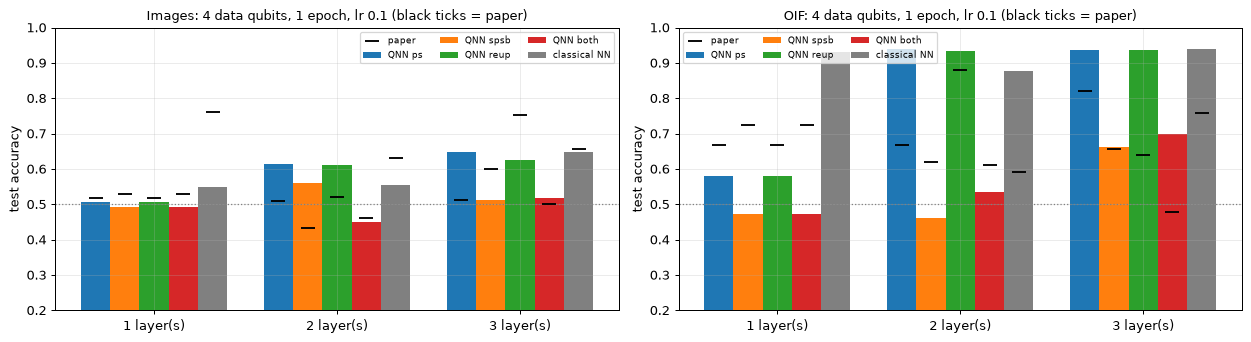

In [42]:
# ---- the 1-epoch grid as bars: test accuracy (protocol B) by number of layers, per method, paper values as black markers
fig, ax = plt.subplots(len(QNN_QUBITS), 2, figsize=(14, 3.9 * len(QNN_QUBITS)), squeeze=False)
for r, N in enumerate(QNN_QUBITS):
    for c, ds in enumerate(("Images", "OIF")):
        a = ax[r, c]; w = 0.16
        for i, m in enumerate(QNN_METHODS + ["nn"]):
            vals, pv = [], []
            for L in QNN_LAYERS:
                d = QNN[(QNN.ds == ds) & (QNN.method == m) & (QNN.N == N) & (QNN.L == L) & (QNN.epochs == 1) & np.isclose(QNN.lr, QNN_GRID_LR) & (QNN.ntrain == QNN_TRAIN)]
                if m == "nn": d = d[d.bs == 16]
                vals.append(d.test_B.mean() if len(d) else np.nan)
                key = (ds, m, "NN" if m == "nn" else "QNN", "B")
                pv.append(PAPER_GRID.get(key, {}).get((N, L), (np.nan, np.nan))[1])
            x = np.arange(len(QNN_LAYERS)) + (i - 2) * w
            a.bar(x, vals, width=w, label=("classical NN" if m == "nn" else "QNN " + m), color=f"C{i}" if m != "nn" else "gray")
            a.scatter(x, pv, color="k", marker="_", s=120, zorder=5, label="paper" if i == 0 else None)
        a.axhline(0.5, color="gray", ls=":", lw=1); a.set_xticks(range(len(QNN_LAYERS))); a.set_xticklabels([f"{L} layer(s)" for L in QNN_LAYERS])
        a.set_ylim(0.2, 1.0); a.set_ylabel("test accuracy"); a.set_title(f"{ds}: {N} data qubits, 1 epoch, lr {QNN_GRID_LR} (black ticks = paper)", fontsize=10); a.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

## 5. Reading the paper critically

All numbers below come from the **FAST_MODE run committed in this file** (BODMAS substitute data, 2 400 + 1 000 file pools, QSVM sizes 500/100 to 2000/400, 1 000-file QNN protocol with a 1 000-file test set, one seed, 4-qubit QNN only). The paper's larger sizes, 7-qubit models, learning-rate scan and 10-epoch deep models were **not run** (`FAST_MODE = False` would run them); the corresponding cells are marked "cannot be checked (not run in FAST_MODE)".

* **The QSVM story survives, with a caveat the paper does not test.** On the Images view the ZZ QSVM reaches 0.725 / 0.792 / 0.752 (500, 1000, 2000 training files), against 0.78 / 0.815 / 0.8125 in the paper: close at 1 000 files, 3 to 6 points lower elsewhere. It matches or beats the default-parameter SVMs (claim C1: +0.012 and +0.015 at 1 000 and 2 000 files, but -0.020 at 500, which lies exactly on the tolerance edge, hence "not reached" by the notebook's strict rule), the sigmoid kernel is far worse (0.31 to 0.36 here, below chance, against 0.54 to 0.61 in the paper), the entanglement-free `Z` map is as good as `ZZ` (mean difference 0.015), and more qubits help: ZZ goes from 0.745 (3 qubits) to 0.867 (7 qubits) at 1 000/200 files, a **+5 point gain over the best default classical SVM at 7 qubits** (paper: +2.5). That is the paper's "quantum advantage on small data" observation, reproduced against the *same kind of baseline* the paper used.
* **But a tuned classical model removes the advantage.** An RBF SVM whose `C` and `gamma` were chosen on the same validation split reaches 0.865 (4 qubits) and 0.885 (7 qubits) at 1 000/200 files, and a random forest 0.853 and 0.880, i.e. at or above every quantum kernel (claim C8, not reached). The paper compares against scikit-learn defaults only. With the kernel bandwidth tuned for the quantum kernel and not for the classical ones, the comparison is not symmetric; here we tuned both and the gap closes. The `Z` map, which is classically computable, being as good as `ZZ` points the same way: entanglement is not what the kernel needs here.
* **The OIF data are saturated.** Our import score alone classifies the test pool with 0.94 accuracy, so every model with 3 to 7 features scores 0.94 to 0.97 and the four feature maps, the four classical kernels and the random forest are indistinguishable (differences of 0.01 are 2 files out of 200). The paper's OIF F1 values of 0.81 to 0.93 (Table 11) are therefore *exceeded* here (0.94 to 0.965), but because our substitute score is stronger than the paper's, not because the quantum model is better. Tables 8 to 10 of the paper are images in the PDF and could not be compared.
* **The QNN is not as hopeless as in the paper, but not better than a classical network either.** After one epoch the parameter-shift QNN scores 0.51 to 0.65 on Images (paper: about 0.50 to 0.52 on 4 000 test files, claim C9 not reached because ours is slightly above chance) and 0.58 / 0.94 / 0.94 on OIF with 1 / 2 / 3 layers (paper: 0.67 to 0.82); more layers help on OIF (claim C12). A small classical network on the same inputs (batch 16) is at 0.55 to 0.65 on Images, equal to the QNN (claim C11 not reached), and at 0.88 to 0.94 on OIF. After three epochs of the 4-qubit / 5-layer model, re-uploading helps on Images (0.711 against 0.645 for plain parameter shift; classical network 0.639) and not on OIF (0.932 against 0.940), so the paper's claim that re-uploading closes the gap is only partly reproduced (C13 holds on average). The paper's conclusion that the QNN never beats the classical network (C15) is **not reached** on Images (0.711 versus 0.639) and equal on OIF (0.940 versus 0.941); our classical network is small (width 8) and untuned, so this says only that the paper's classical comparison is a weak one, not that the QNN wins.
* **SPSB is slow to learn per epoch, as the paper says.** With 3 epochs SPSB reaches 0.789 on OIF against 0.940 for the exact gradient, and 0.603 against 0.645 on Images; the combination with re-uploading reaches 0.912 on OIF (claim C14, not reached for the *mean* gap of -0.10 after only 3 epochs; the paper needs 10 epochs). It needs only 3 circuit runs per training file instead of `2 x parameters + 1` (claim C18, true by construction).
* **Statistical caution.** One seed per QNN cell, 1 000 test files (the paper's 200-file protocol has a standard error of about 3.5 points), single draws of the training sets in the QNN grid, 2 draws for the QSVM sizes up to 2 000: differences below about 3 points are noise. The paper's own tables jump by 10 to 40 points between neighbouring settings (for example OIF 0.667 to 0.879 to 0.640 over 1 to 3 re-uploading layers), which a single run cannot support.
* **Data.** Everything is BODMAS-only static features: the byte-histogram "image" is a different object from the paper's 64 x 64 byte picture, the import score is a supervised stand-in, and the file collection is a single year. BODMAS timestamps and families make a time-aware split possible (exercise suggestion: train on early files, test on late ones), which would test the paper's motivation, generalisation to unseen malware, that neither the paper nor this notebook addresses.
* **Cost.** The QNN simulation is exact; on hardware every number would carry shot noise, and the parameter-shift rule would need `2 x parameters + 1` circuit runs per file (about 1e5 per training run here), which is why SPSB matters, and which the paper discusses only qualitatively.

## 6. Exercises

1. **Bandwidth.** Set `BW_GRID = (1.0,)` (no tuning) and rerun the QSVM tables. Which feature maps lose accuracy, and why does the `ZZ` map (with its `(pi - x_j)(pi - x_k)` phases) depend so much on the angle scale?
2. **A fair classical rival.** The notebook adds an RBF SVM with `C` and `gamma` tuned on the same validation split. Add the same tuning for the polynomial kernel, then add a gradient-boosted tree model on the same 4 inputs. Does any quantum kernel stay ahead on the Images view?
3. **Entangler choice.** The QNN's CNOT pattern is a `# CHOICE:` (the paper's figure is not in the text). Replace the chain by a ring or a star (`QNNSim.src` and the loop in `qnn_circuit` must change together; the equivalence assertions will tell you if they disagree). Does the parameter count change? Does the accuracy?
4. **SPSB step size.** `QNN_SPSB_EPS = 0.1` is not given in the paper. Try 0.5 and 0.01 on the OIF data (4 qubits, 5 layers) and plot the training curves. For a sine-like circuit output, what is the exact relation between the finite-difference estimate and the true directional derivative?
5. **Cost accounting.** Using the `circuit runs` column, compute how long the parameter-shift runs would take on a device that executes 1 000 circuits per minute. Compare with the paper's "days instead of hours" remark and decide how many shots per circuit would make SPSB cheaper still.

In [43]:
# ---- housekeeping: report the run time and remove large cached files (above 50 MB) from DATA_DIR
print(f"total run time of this notebook: {(time.time() - T_NOTEBOOK) / 60:.1f} min   (FAST_MODE={FAST_MODE})")
if CLEAN_CACHE_AT_END:
    for f in os.listdir(DATA_DIR):
        p = os.path.join(DATA_DIR, f)
        if os.path.isfile(p) and os.path.getsize(p) > 50e6:
            os.remove(p); print("removed cached file", f)

total run time of this notebook: 28.6 min   (FAST_MODE=True)
